# Hospitality Guest Survival Analysis (time-to-next-booking)
End-to-end notebook: synthetic data → EDA → classical / tree / GPU deep survival models → evaluation.
Reuses the modules in `src/` (API code intentionally excluded). Models are kept in memory only (the tuned Random Survival Forest pickles to >7 GB).

In [1]:
import os, sys, warnings, time, json
from pathlib import Path
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Image
from src.utils import load_config, resolve, get_device, seed_everything
from src import data_generator, eda_visuals, evaluate
from src.features import load_and_split
from src.train_pipeline import tune, build_final_models
from src.registry import BASELINES
from sklearn.model_selection import train_test_split

cfg = load_config()
seed_everything(cfg["seed"])
dev = get_device(cfg)
print("device:", dev.torch_device, "|", dev.name)
# notebook-specific output folders so the committed pipeline outputs are untouched
NB_OUT = ROOT / "output" / "notebook"
for d in ("data_visuals", "comparison_graphs", "training_logs"):
    (NB_OUT / d).mkdir(parents=True, exist_ok=True)
cfg["paths"].update(data_visuals="output/notebook/data_visuals", comparison_graphs="output/notebook/comparison_graphs",
                    training_logs="output/notebook/training_logs", data="output/notebook/guests.csv")

device: cuda | NVIDIA GeForce RTX 3090


## 1. Synthetic guest data (N = 15,000, ~30 % right-censored)

In [2]:
df = data_generator.generate(cfg["data"]["n_samples"], cfg["data"]["target_censoring"],
                             cfg["data"]["max_follow_up_days"], cfg["seed"])
df.to_csv(resolve(cfg, "data"), index=False)
display(df.head())
display(df.describe().T.round(2))

2026-11-22 16:01:25,226 | INFO    | data_generator | Generated 15000 guests | censored=30.0% | median duration=131d | c_hi=758


,guest_id,loyalty_tier,adr_avg,length_of_stay_avg,lead_time_days,days_since_last_stay,total_prior_stays,ancillary_spend_ratio,promo_email_open_rate,app_sessions_30d,channel_direct,trip_purpose_business,seasonality_index,duration_days,event_observed
0,G000000,Gold,139.42,1.77,82.8,55.0,10,0.2060,0.4040,10,1,0,0.7752,229.0,1
1,G000001,Member,137.29,3.39,47.3,120.4,2,0.1131,0.1441,2,0,0,1.1270,325.0,0
2,G000002,Gold,203.69,2.80,19.2,88.7,7,0.2311,0.5884,15,0,0,0.7430,184.0,1
3,G000003,Silver,221.08,1.40,9.0,15.0,11,0.3843,0.4106,8,0,1,0.9492,45.1,1
4,G000004,Member,194.18,1.06,9.3,280.0,1,0.1491,0.3478,3,0,0,0.9090,89.9,0


,count,mean,std,min,25%,50%,75%,max
adr_avg,15000.0,164.11,62.44,55.00,120.08,153.28,195.37,647.18
length_of_stay_avg,15000.0,2.83,1.97,1.00,1.31,2.28,3.69,18.53
lead_time_days,15000.0,40.77,33.54,0.40,16.80,31.30,54.90,308.20
days_since_last_stay,15000.0,106.86,62.83,5.00,61.30,94.70,138.90,572.90
total_prior_stays,15000.0,4.93,2.99,1.00,3.00,4.00,7.00,23.00
ancillary_spend_ratio,15000.0,0.27,0.15,0.00,0.16,0.25,0.37,0.99
promo_email_open_rate,15000.0,0.36,0.17,0.01,0.23,0.35,0.48,1.00
app_sessions_30d,15000.0,7.56,4.54,0.00,4.00,7.00,10.00,30.00
channel_direct,15000.0,0.41,0.49,0.00,0.00,0.00,1.00,1.00
trip_purpose_business,15000.0,0.41,0.49,0.00,0.00,0.00,1.00,1.00


## 2. Exploratory visuals (300 DPI PNGs saved, displayed inline)

2026-11-22 16:01:25,581 | INFO    | eda | saved D:\Ramakrishna_D\Python\GitProjects\machinelearning\Survival_modeling\hospitality_survival_mlops\output\notebook\data_visuals\01_censoring_vs_event_distribution.png


2026-11-22 16:01:25,905 | INFO    | eda | saved D:\Ramakrishna_D\Python\GitProjects\machinelearning\Survival_modeling\hospitality_survival_mlops\output\notebook\data_visuals\02_km_by_loyalty_tier.png


2026-11-22 16:01:26,160 | INFO    | eda | saved D:\Ramakrishna_D\Python\GitProjects\machinelearning\Survival_modeling\hospitality_survival_mlops\output\notebook\data_visuals\03_km_by_trip_purpose.png


2026-11-22 16:01:26,402 | INFO    | eda | saved D:\Ramakrishna_D\Python\GitProjects\machinelearning\Survival_modeling\hospitality_survival_mlops\output\notebook\data_visuals\04_nelson_aalen_by_channel.png


2026-11-22 16:01:26,886 | INFO    | eda | saved D:\Ramakrishna_D\Python\GitProjects\machinelearning\Survival_modeling\hospitality_survival_mlops\output\notebook\data_visuals\05_feature_correlation_heatmap.png


2026-11-22 16:01:28,066 | INFO    | eda | saved D:\Ramakrishna_D\Python\GitProjects\machinelearning\Survival_modeling\hospitality_survival_mlops\output\notebook\data_visuals\06_feature_violins_by_event.png


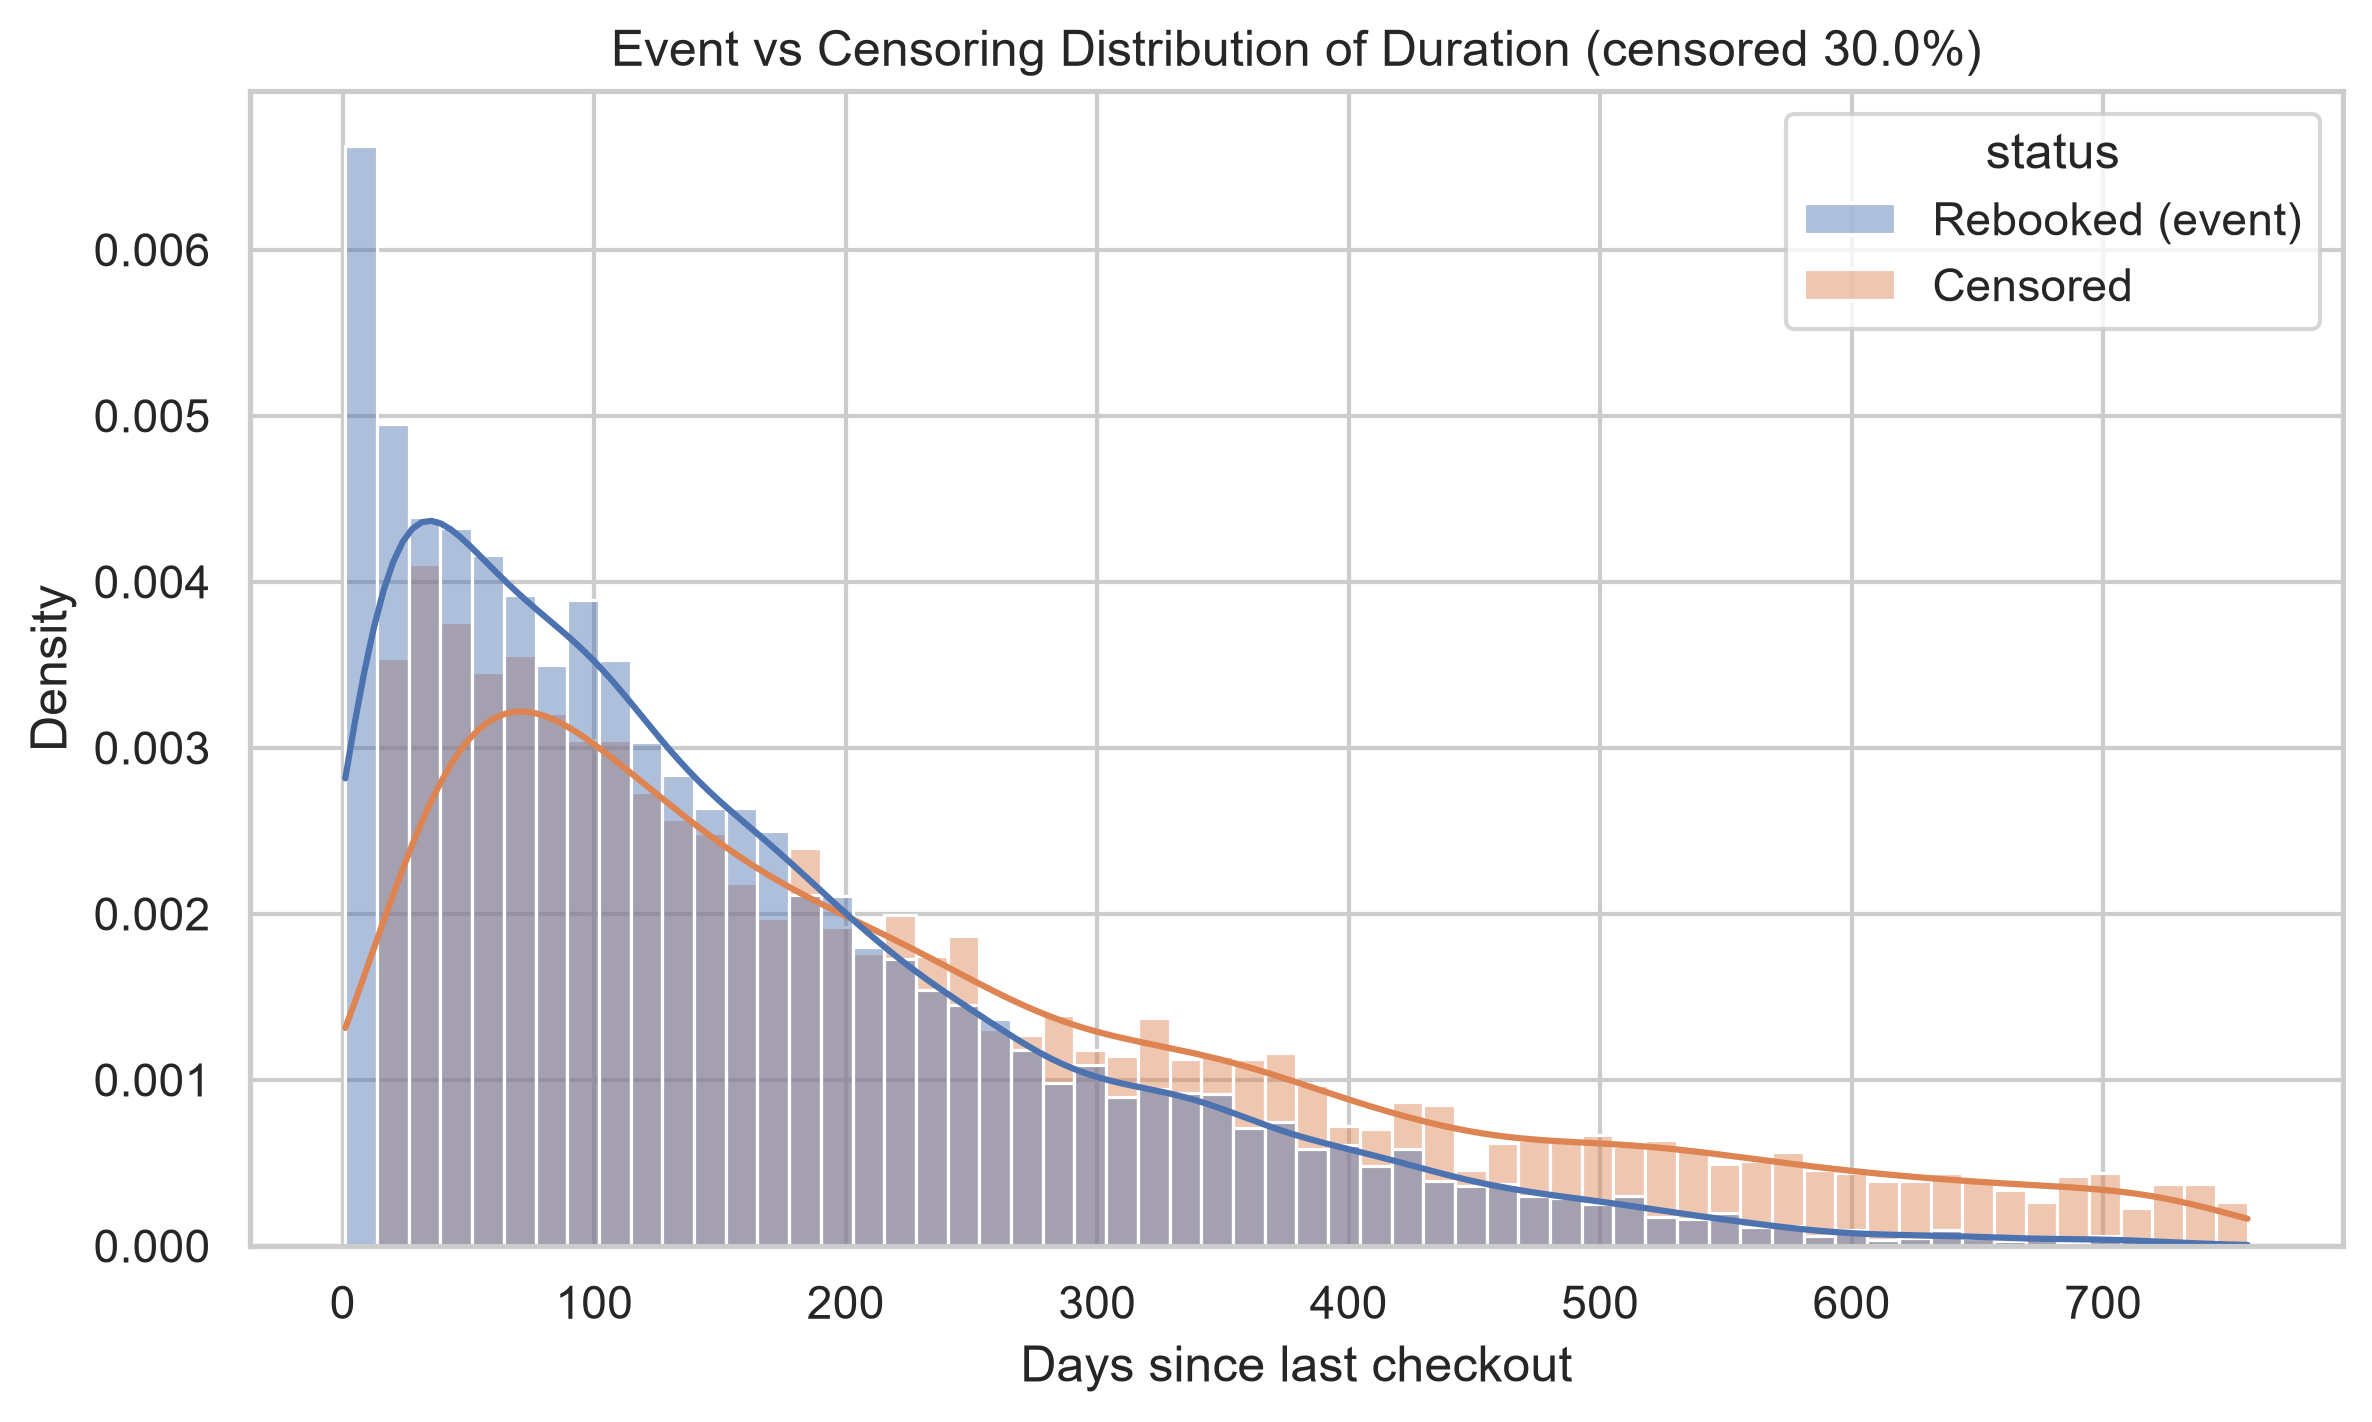

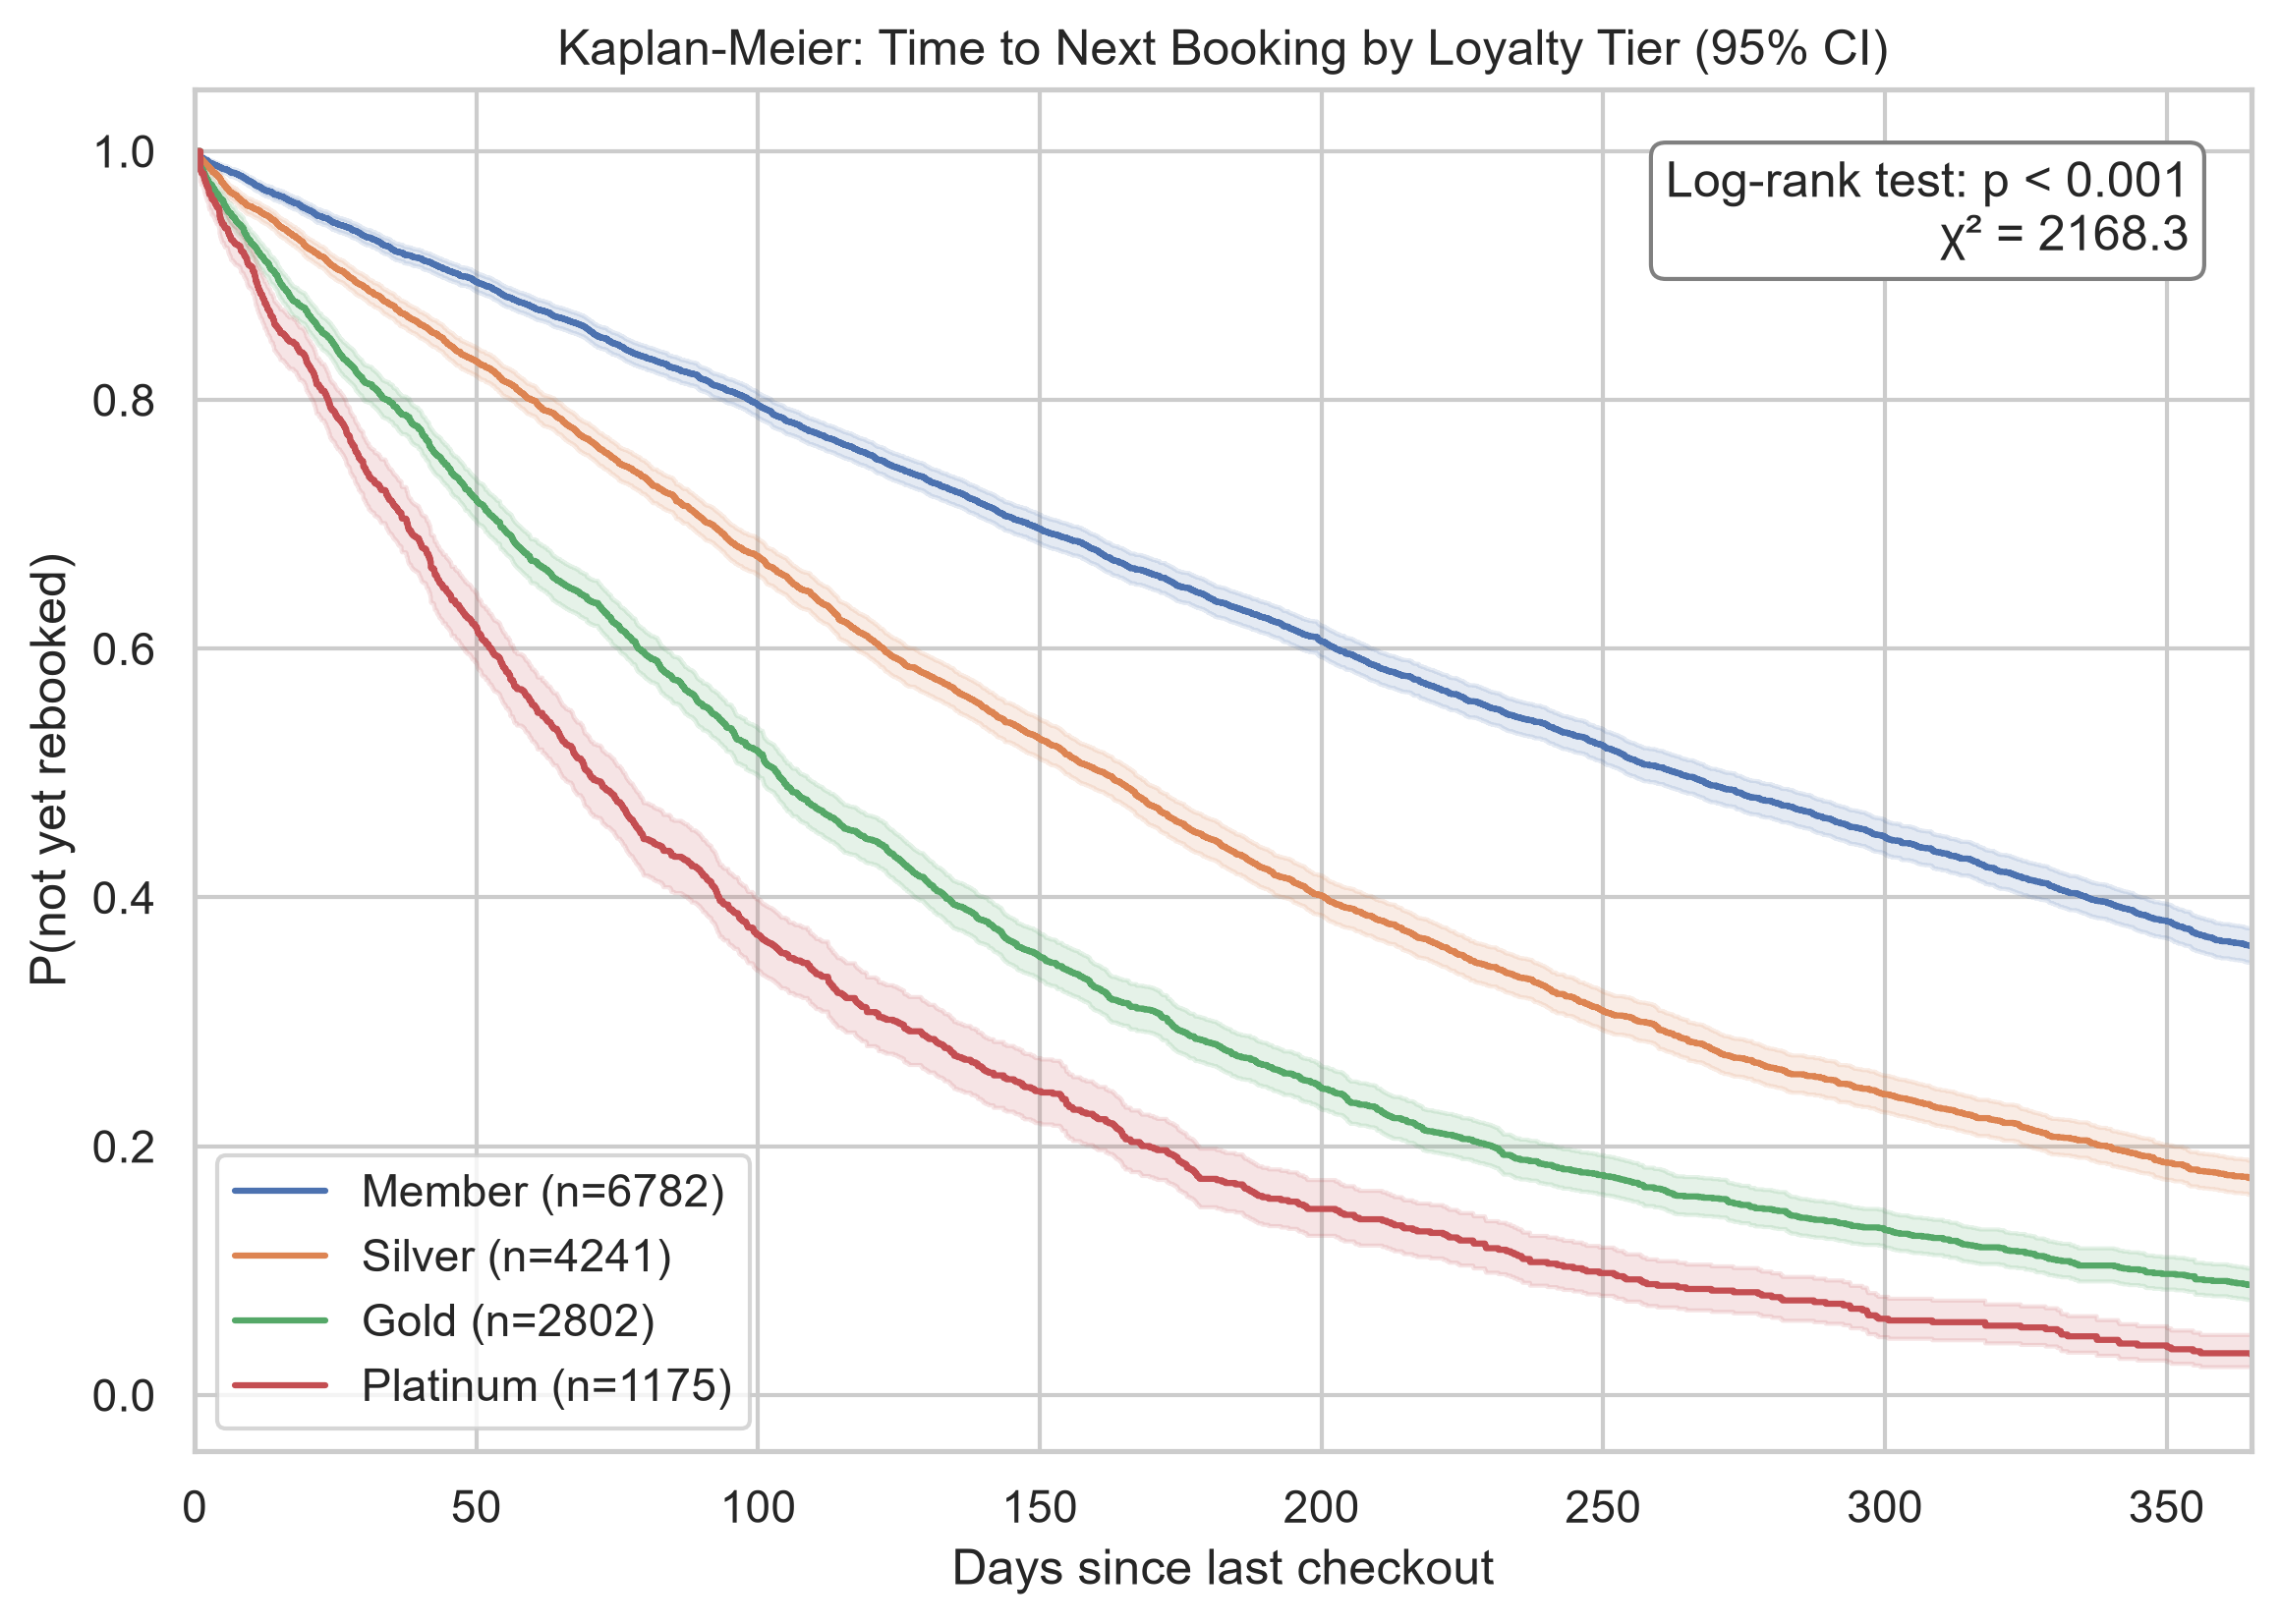

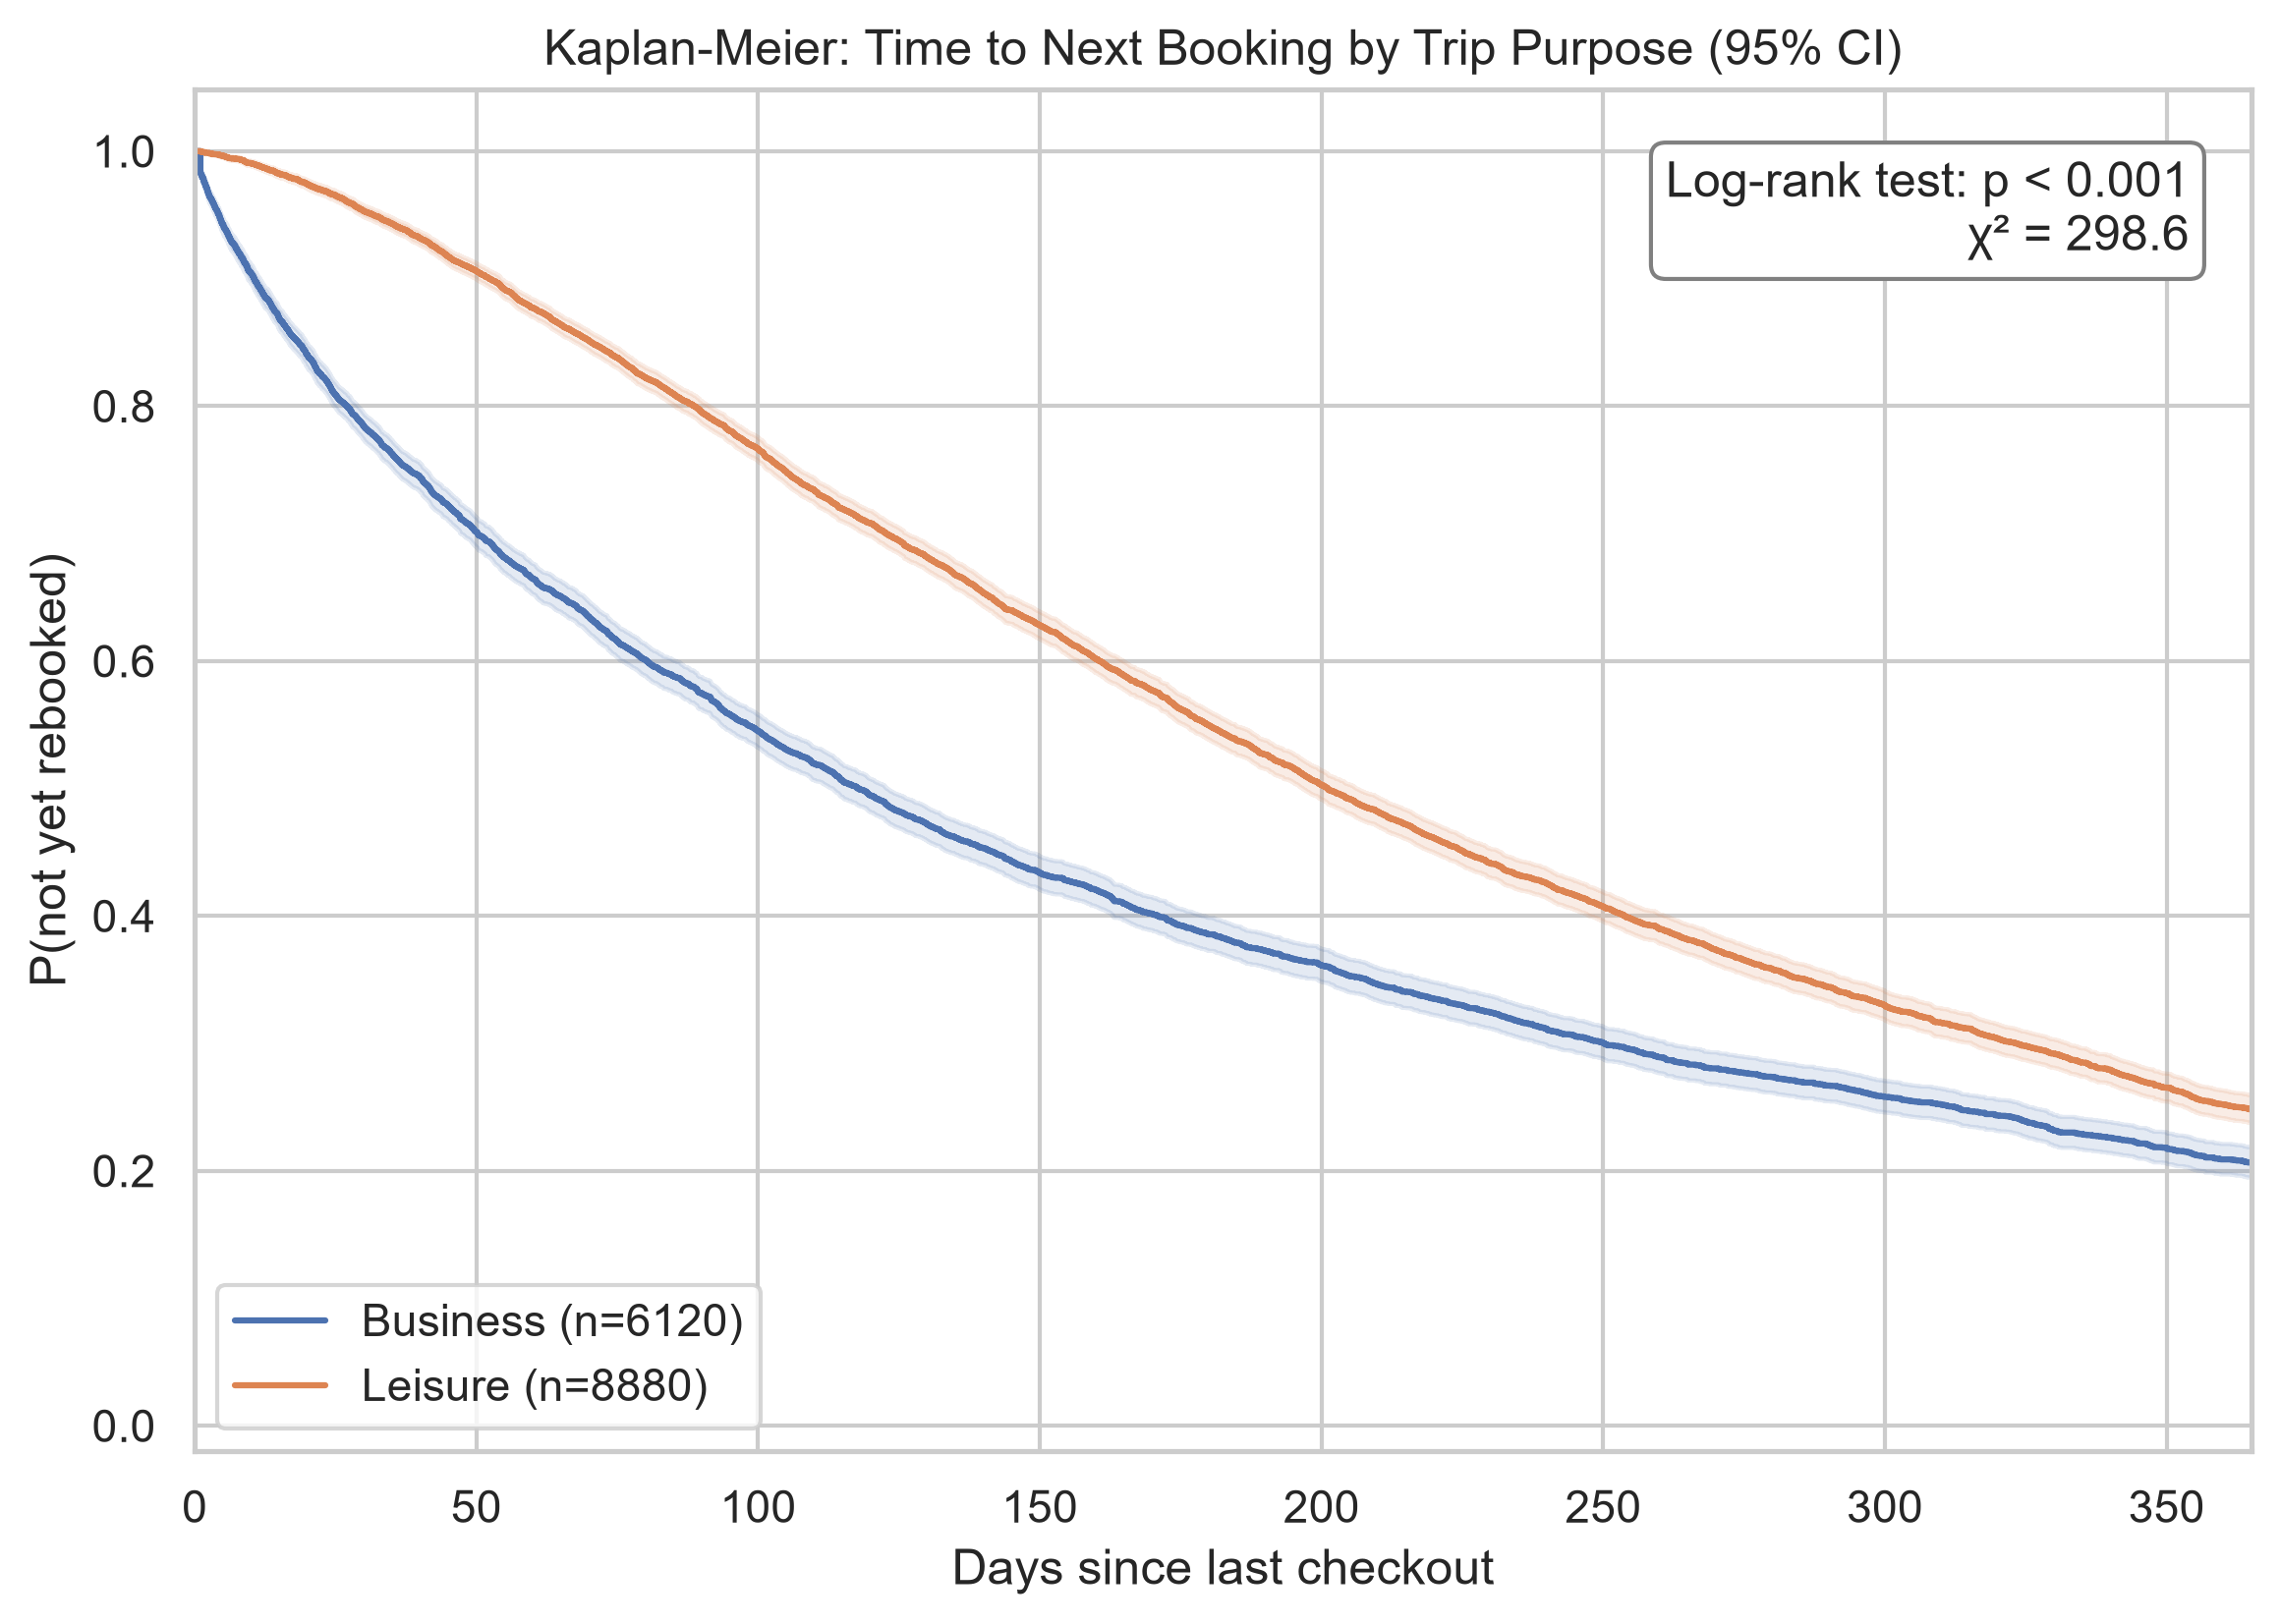

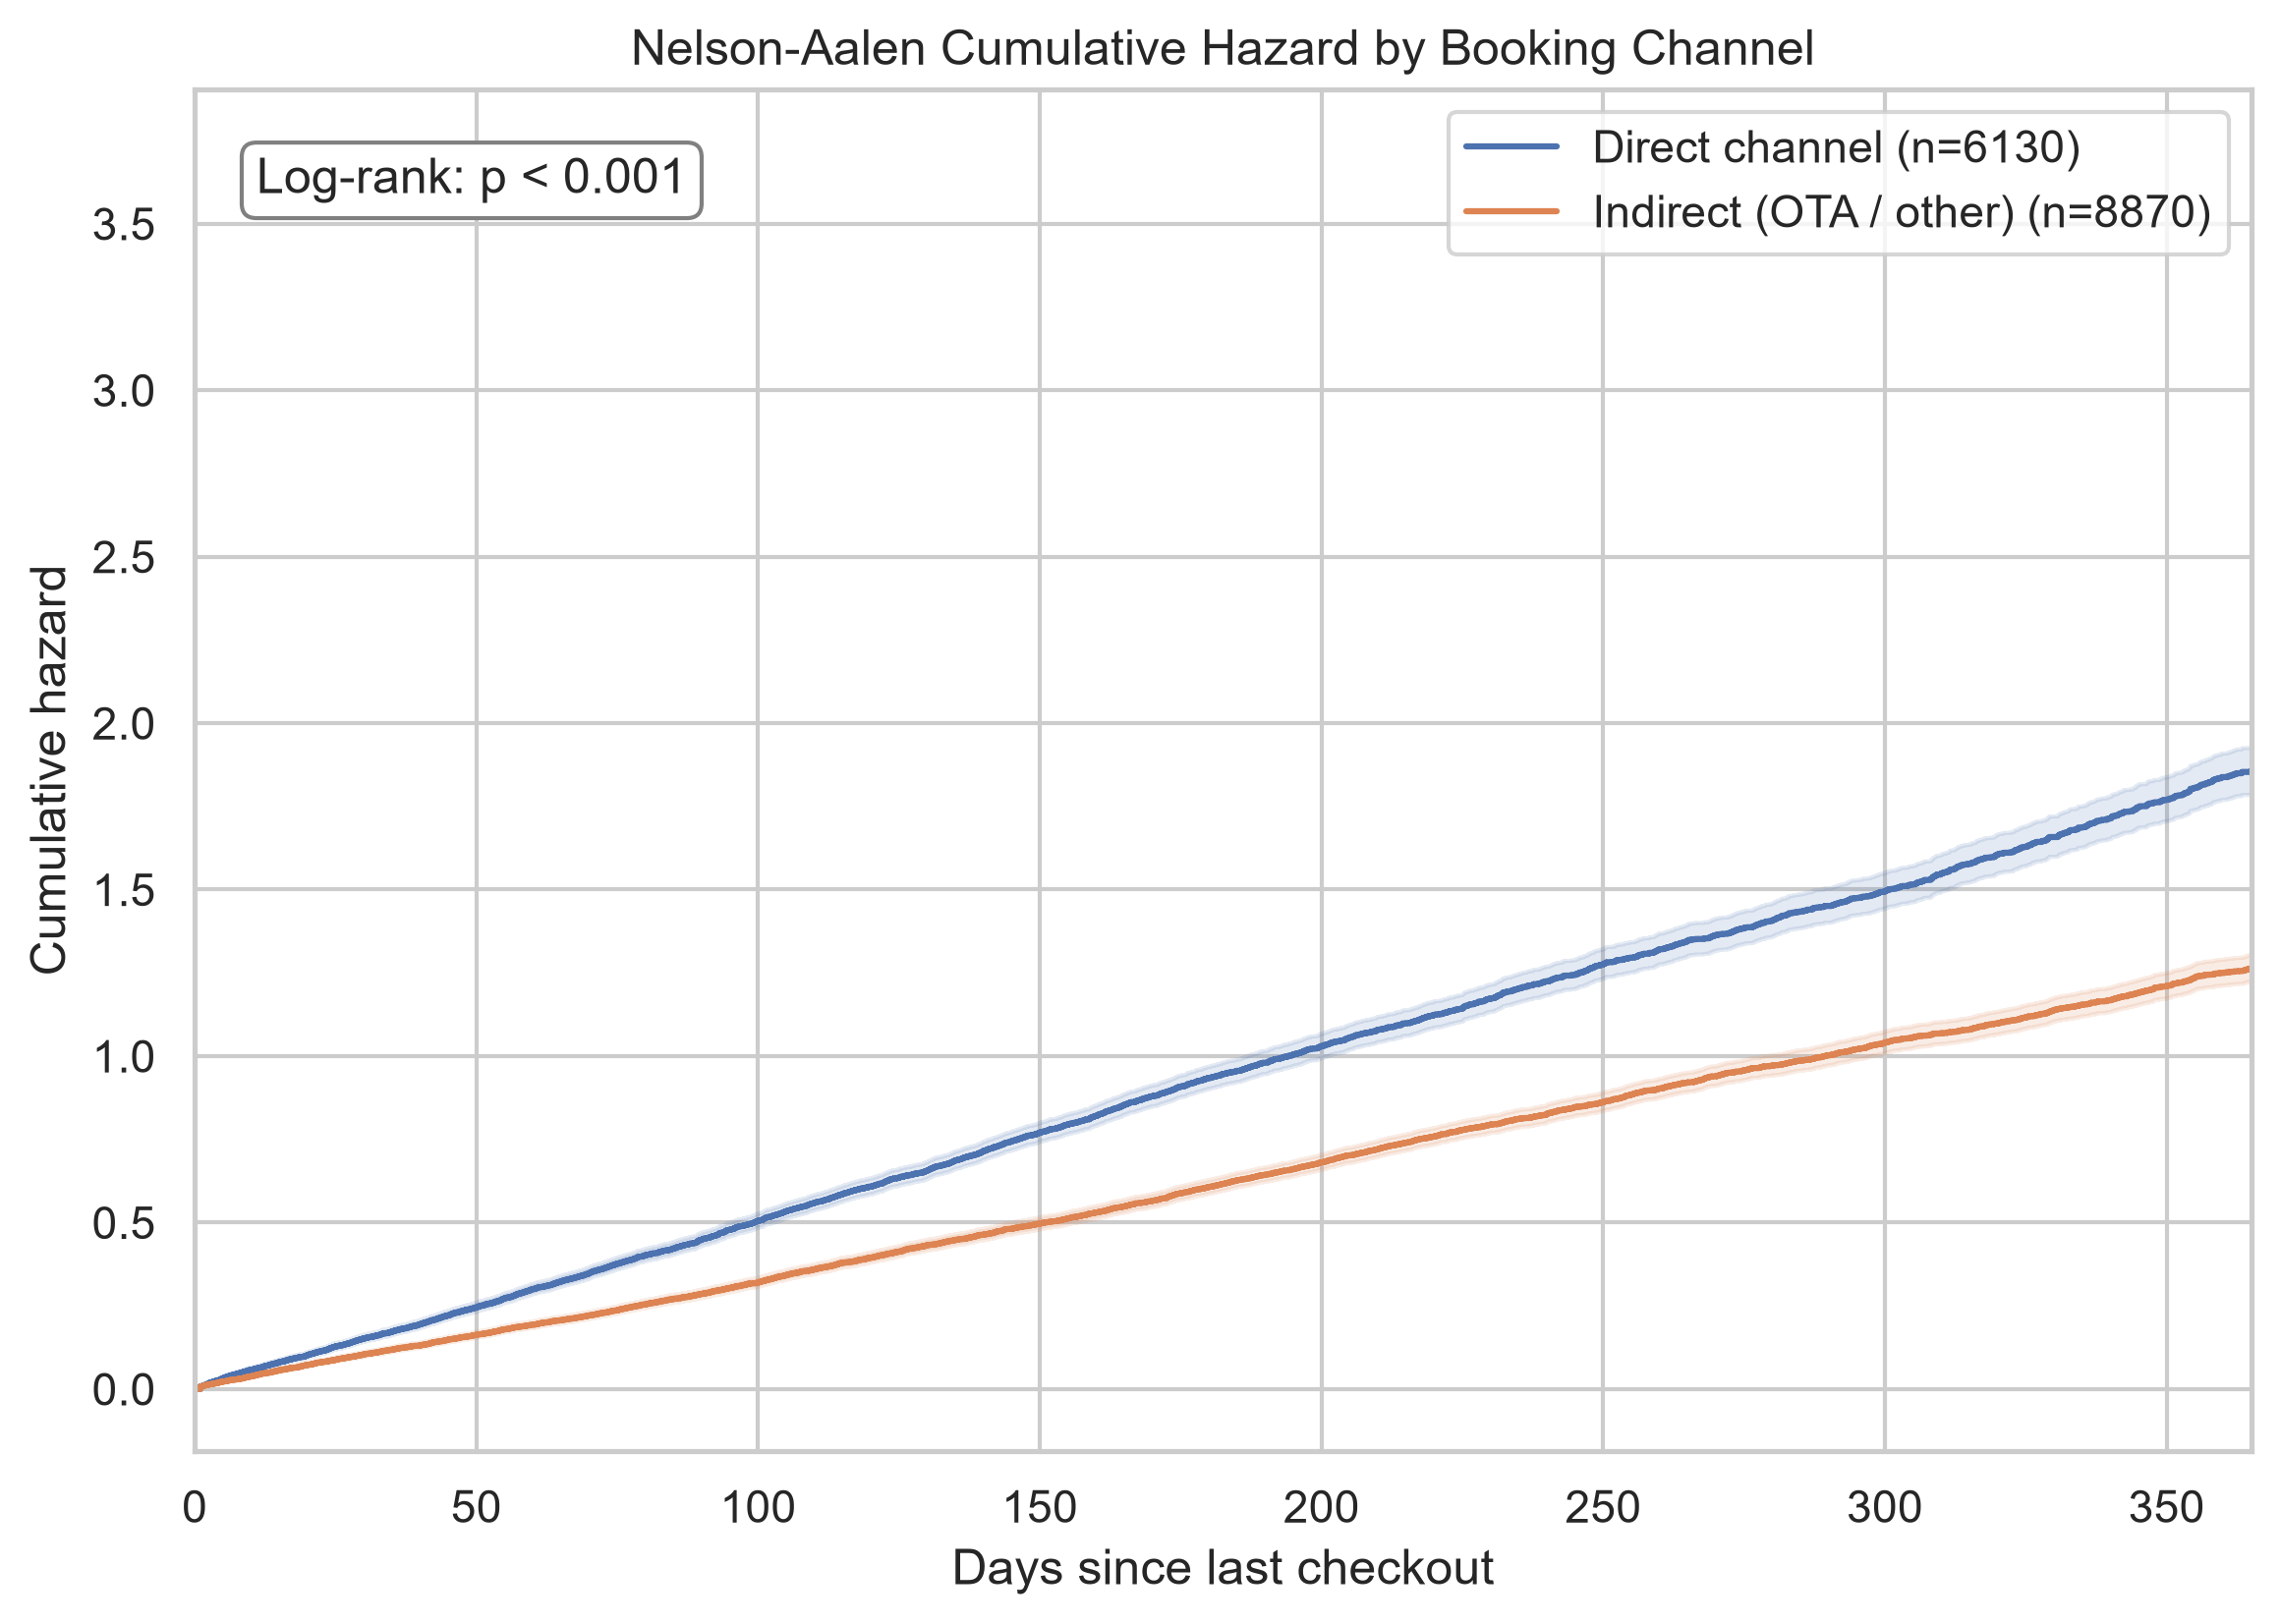

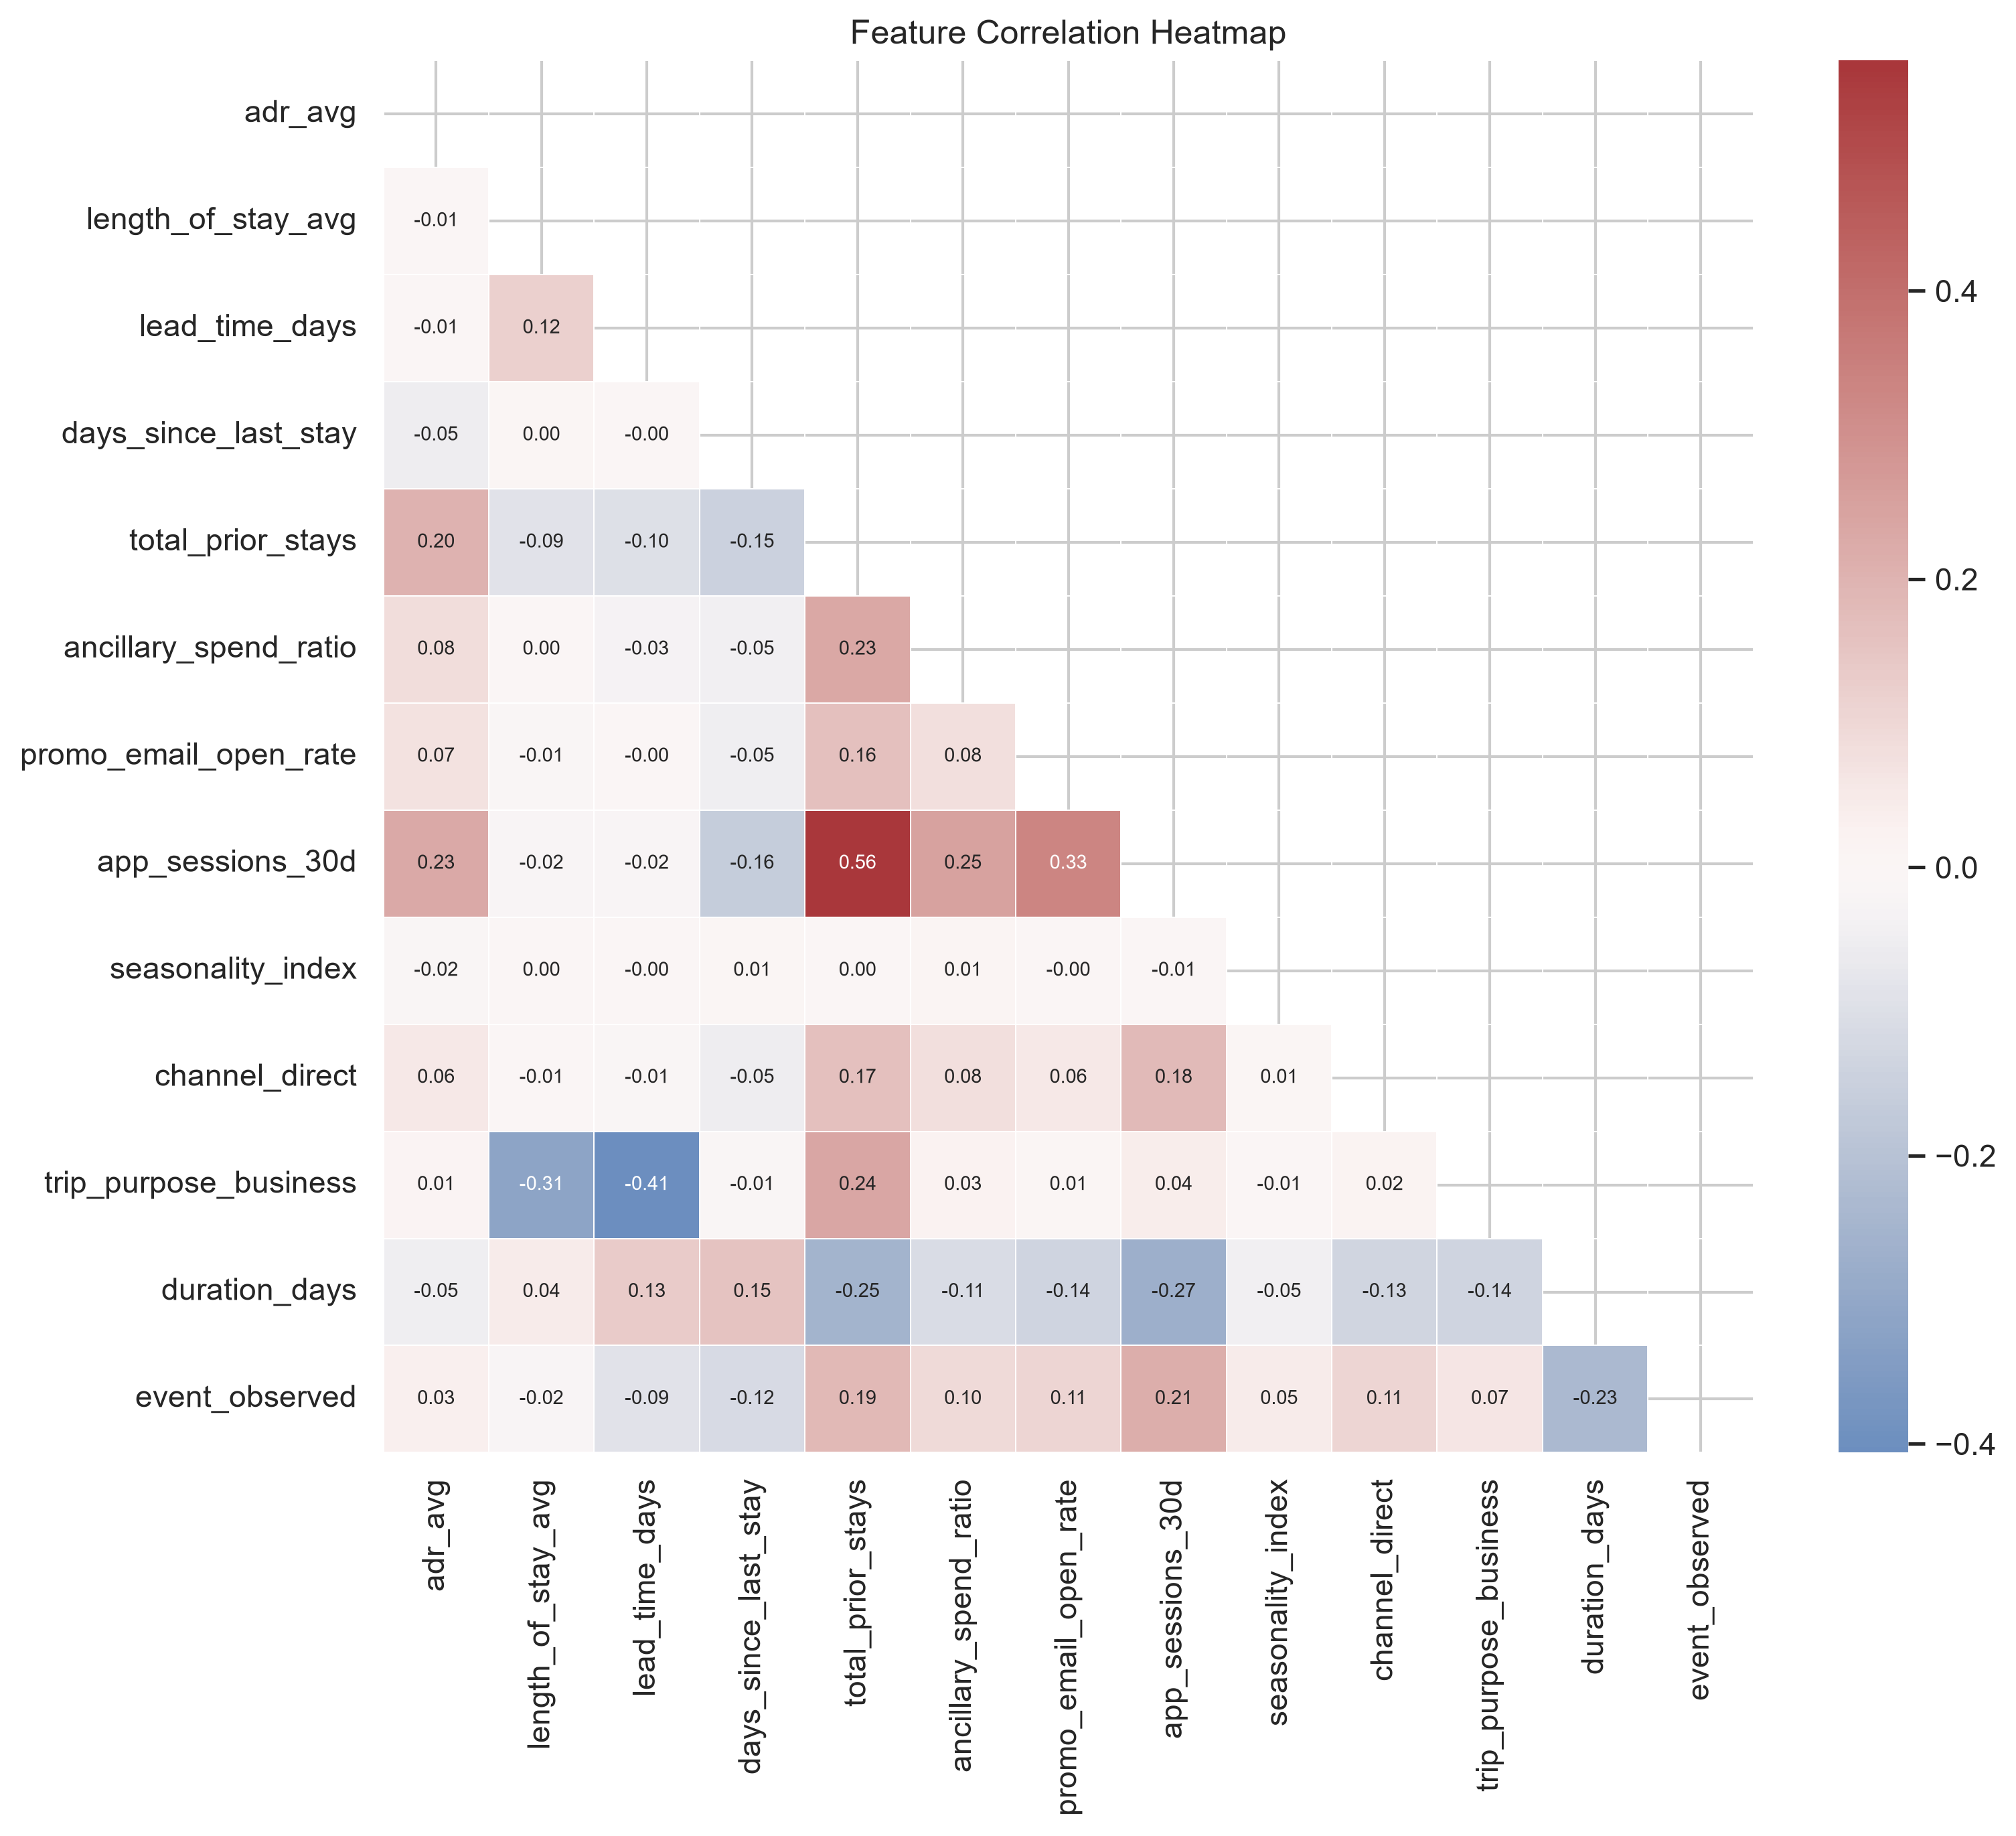

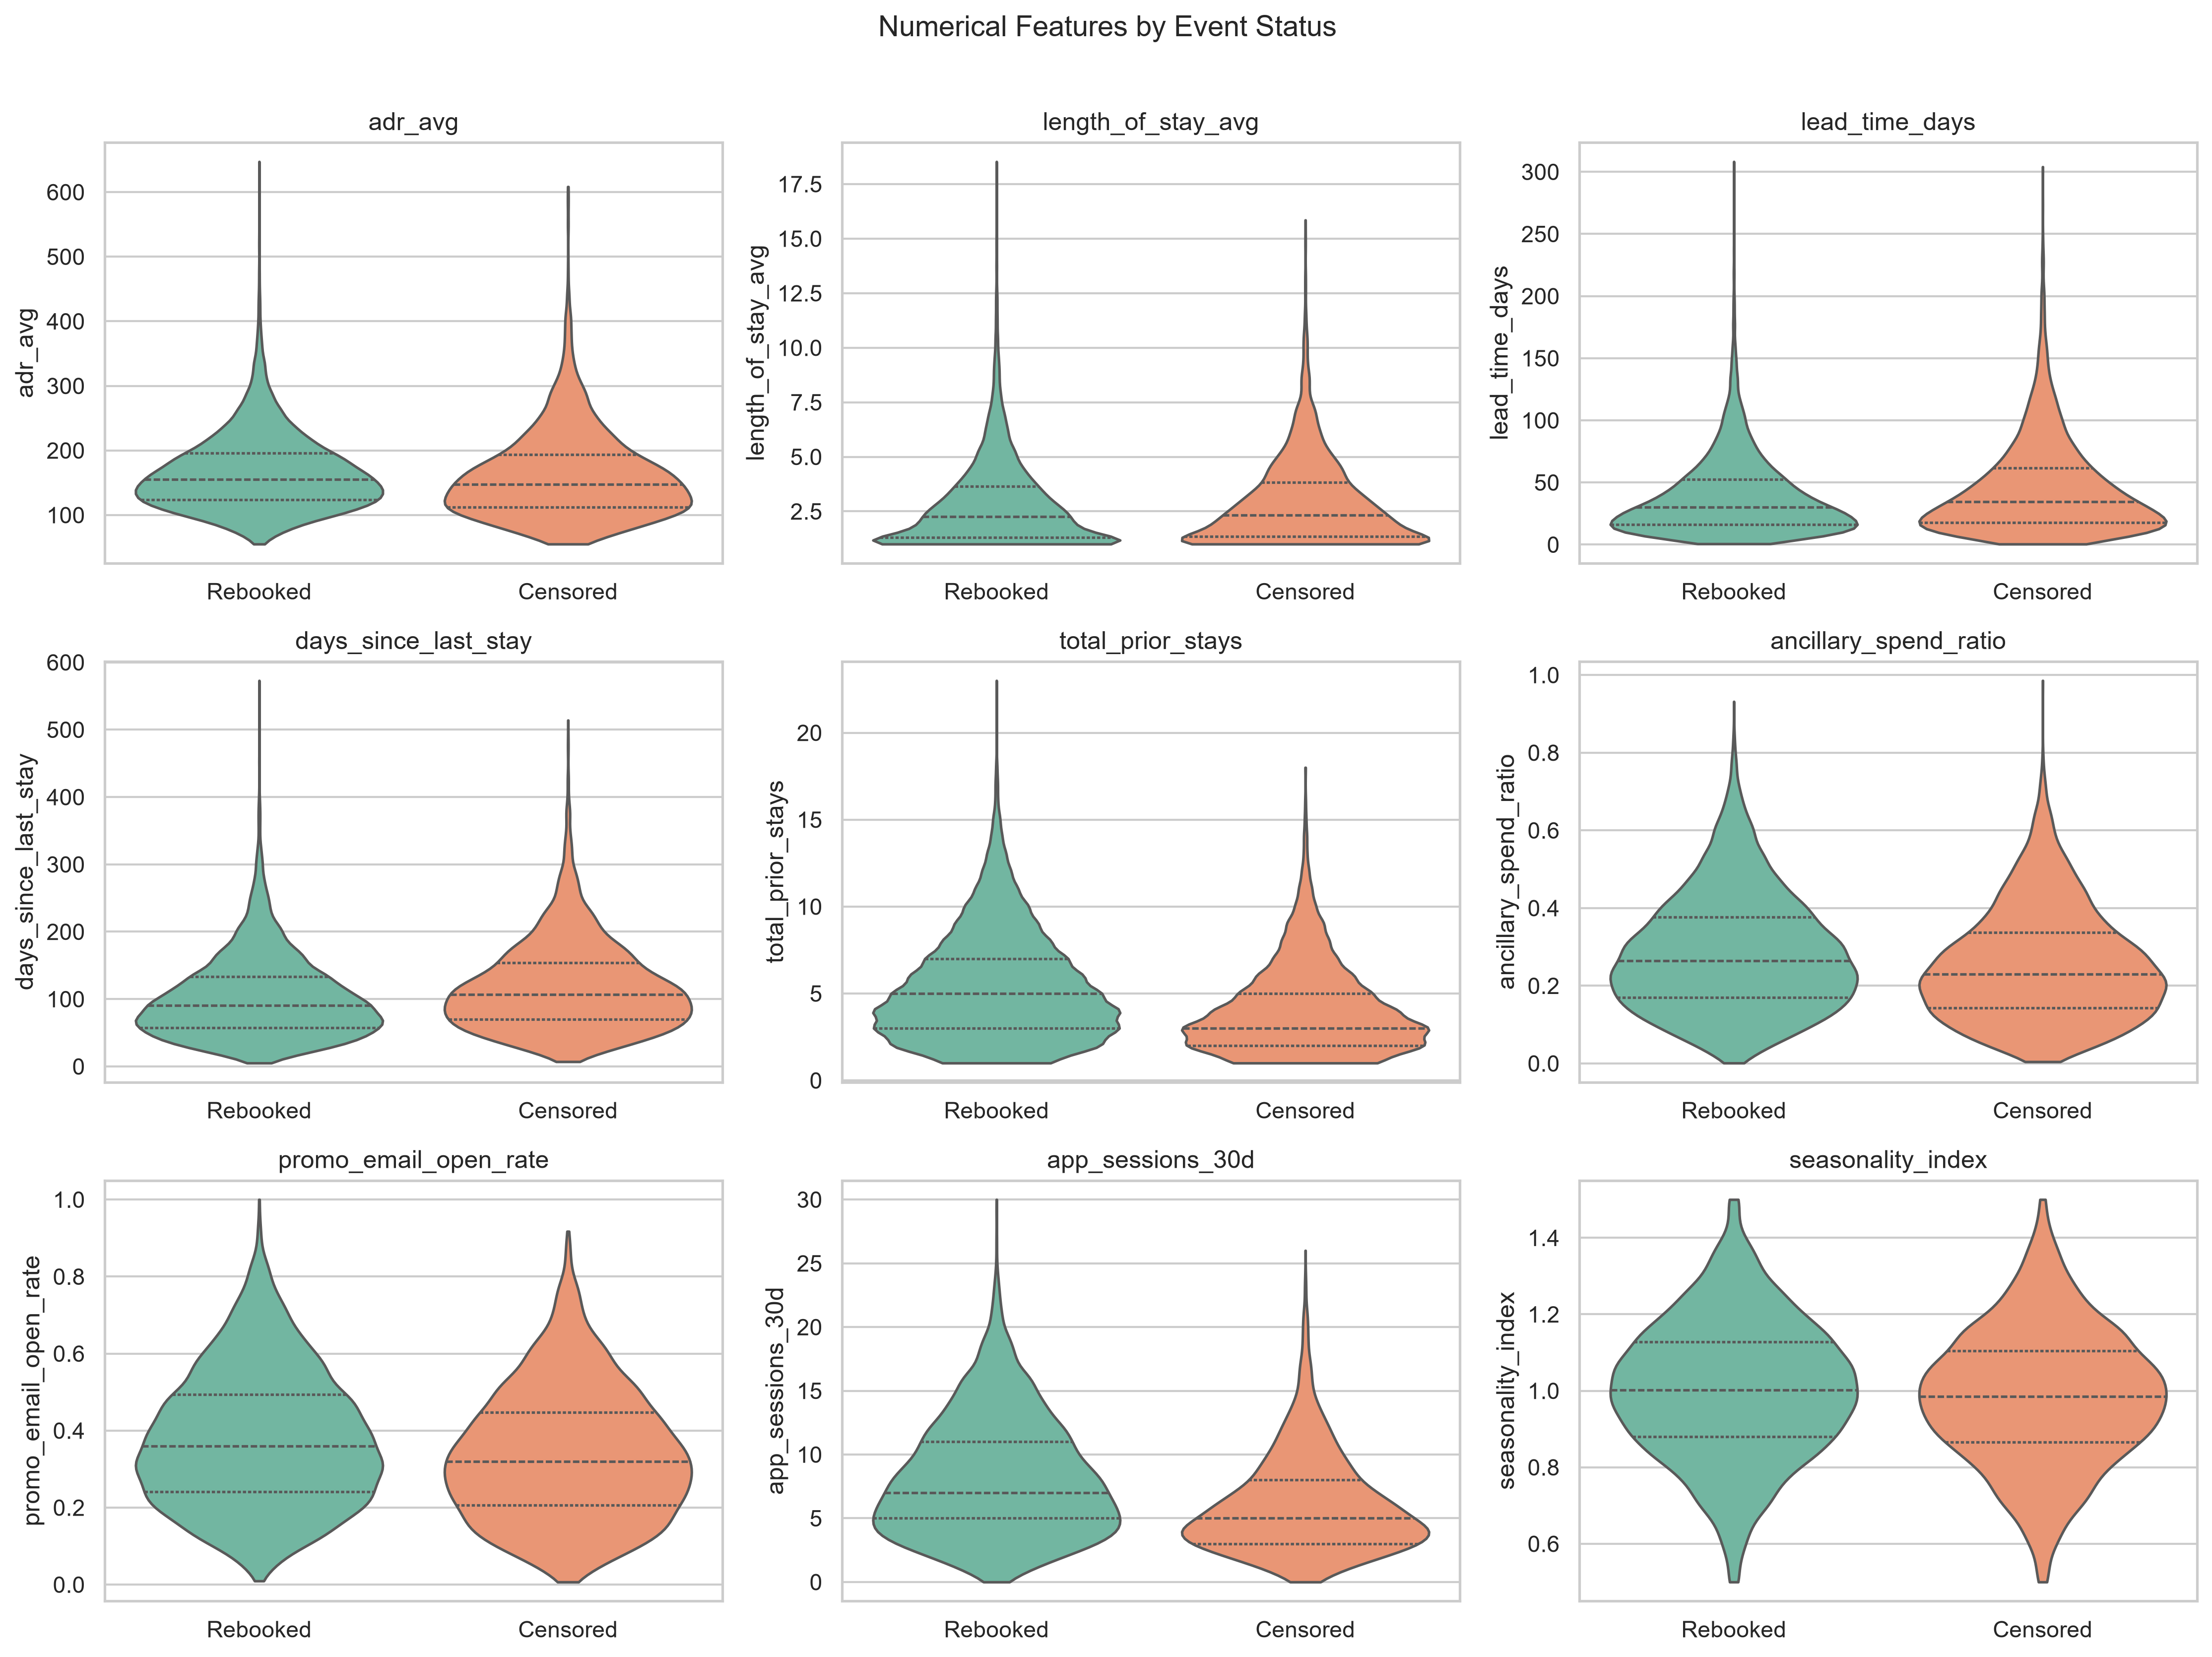

In [3]:
paths = eda_visuals.run(df, cfg)
for p in paths:
    display(Image(filename=str(p), width=800))

## 3. Features and stratified 80/20 hold-out split

In [4]:
split = load_and_split(resolve(cfg, "data"), cfg["split"]["test_size"], cfg["seed"])
print("train", split["X_train"].shape, "test", split["X_test"].shape,
      "| event rate", split["e_train"].mean().round(3), split["e_test"].mean().round(3))
display(split["X_train"].head())

train (12000, 17) test (3000, 17) | event rate 0.7 0.7


,tier_Silver,tier_Gold,tier_Platinum,channel_direct,trip_purpose_business,log_adr,length_of_stay_avg,log_lead_time,log_days_since_last_stay,log_prior_stays,ancillary_spend_ratio,promo_email_open_rate,log_app_sessions,seasonality_index,log_monetary,lead_x_business,engagement_score
0,0.0,1.0,0.0,1.0,0.0,1.069345,0.734057,1.401578,1.458444,1.649397,-0.090147,-0.850187,0.700285,-0.280609,2.034372,-0.790443,0.137652
1,0.0,0.0,0.0,0.0,1.0,-1.164072,-0.461832,-0.619221,2.039750,-0.091609,0.237971,-0.753249,-1.552433,-0.676359,-0.627743,1.089970,-1.510081
2,0.0,0.0,1.0,0.0,0.0,-0.524140,-0.127389,0.320704,-0.445892,1.808574,-0.395497,-1.093101,1.118416,0.486572,1.022509,-0.790443,0.340756
3,1.0,0.0,0.0,0.0,0.0,0.136329,-0.928026,-0.215381,0.902838,-0.535365,-0.468487,1.219142,0.148145,0.785043,-1.103153,-0.790443,0.668124
4,0.0,0.0,0.0,1.0,1.0,-1.049161,-0.629054,-0.220086,0.460969,-0.091609,1.062284,2.024862,0.148145,2.003248,-0.776788,1.306000,1.036144


## 4. Hyper-parameter tuning (Optuna, inner validation split of the training set)

In [5]:
idx = np.arange(len(split["X_train"]))
i_tr, i_va = train_test_split(idx, test_size=0.2, random_state=cfg["seed"], stratify=split["e_train"])
inner = dict(X_tr=split["X_train"].iloc[i_tr], t_tr=split["t_train"][i_tr], e_tr=split["e_train"][i_tr],
             X_va=split["X_train"].iloc[i_va], t_va=split["t_train"][i_va], e_va=split["e_train"][i_va])
tuned, scores = {}, {}
for name in ("coxph", "rsf", "xgb_cox", "xgb_aft", "deepsurv", "deephit"):
    tuned[name], scores[name] = tune(name, cfg, dev, inner)
pd.Series(scores, name="best validation C-index").round(4).to_frame()

2026-11-22 16:02:20,709 | INFO    | pipeline | Optuna[coxph] 12 trials in 52.5s | best val C=0.6737 | {'penalizer': 0.008179499475211672, 'l1_ratio': 0.5247564316322378}


2026-11-22 16:03:39,177 | INFO    | pipeline | Optuna[rsf] 6 trials in 78.5s | best val C=0.6747 | {'min_samples_leaf': 22, 'max_depth': 16, 'max_features': 'sqrt'}


2026-11-22 16:03:51,530 | INFO    | pipeline | Optuna[xgb_cox] 15 trials in 12.3s | best val C=0.6812 | {'learning_rate': 0.01588206797573834, 'max_depth': 6, 'subsample': 0.5025676829508181, 'colsample_bytree': 0.8982564730010701, 'min_child_weight': 10.254296467402499, 'reg_lambda': 4.449444041436482}


2026-11-22 16:04:01,835 | INFO    | pipeline | Optuna[xgb_aft] 15 trials in 10.3s | best val C=0.6845 | {'learning_rate': 0.026284086323262772, 'max_depth': 2, 'subsample': 0.7192102759534911, 'colsample_bytree': 0.936223356728685, 'min_child_weight': 10.745297520225684, 'reg_lambda': 0.16797793128854696, 'aft_loss_distribution': 'logistic', 'aft_loss_distribution_scale': 1.7160762944776629}


2026-11-22 16:04:09,223 | INFO    | deep | deepsurv early stop at epoch 24 (best val 6.8002)


2026-11-22 16:04:13,323 | INFO    | deep | deepsurv early stop at epoch 52 (best val 6.7960)


... (2 outputs left out)

2026-11-22 16:04:23,772 | INFO    | deep | deephit early stop at epoch 68 (best val 1.6311)


2026-11-22 16:04:26,416 | INFO    | deep | deephit early stop at epoch 68 (best val 1.6410)


2026-11-22 16:04:34,904 | INFO    | pipeline | Optuna[deephit] 6 trials in 16.9s | best val C=0.6781 | {'hidden': '128-64', 'dropout': 0.14561457009902096, 'lr': 0.001095266274863256, 'weight_decay': 3.6138942712165278e-06, 'alpha': 0.7876433945605654, 'sigma': 0.11623364244752171}


,best validation C-index
coxph,0.6737
rsf,0.6747
xgb_cox,0.6812
xgb_aft,0.6845
deepsurv,0.6813
deephit,0.6781


## 5. Train all models (KM, Nelson-Aalen, CoxPH, Weibull/Log-Normal AFT, RSF, XGBoost Cox/AFT on CUDA, DeepSurv, DeepHit on CUDA)

In [6]:
models = build_final_models(cfg, dev, tuned)
fitted = {}
for m in models:
    m.fit(split["X_train"], split["t_train"], split["e_train"])
    if m.name == "coxph":
        ph = m.ph_violations(); print("CoxPH PH-test violations:", list(ph.index[ph.violates_PH]))
    if hasattr(m, "history"):
        m.save_history(resolve(cfg, "training_logs"))
    fitted[m.name] = m
    print(f"{m.name:24s} {getattr(m, 'device', 'cpu'):5s} {m.train_seconds:7.2f}s")

kaplan_meier             cpu      0.01s
nelson_aalen             cpu      0.01s


CoxPH PH-test violations: ['trip_purpose_business']
coxph                    cpu      5.24s


weibull_aft              cpu      0.26s


lognormal_aft            cpu      0.56s


random_survival_forest   cpu     22.50s


xgboost_cox              cuda     1.15s


xgboost_aft              cuda     0.41s


2026-11-22 16:05:09,360 | INFO    | deep | deepsurv early stop at epoch 93 (best val 6.4898)


deepsurv                 cuda     2.81s


deephit                  cuda     4.12s


### Deep model loss curves

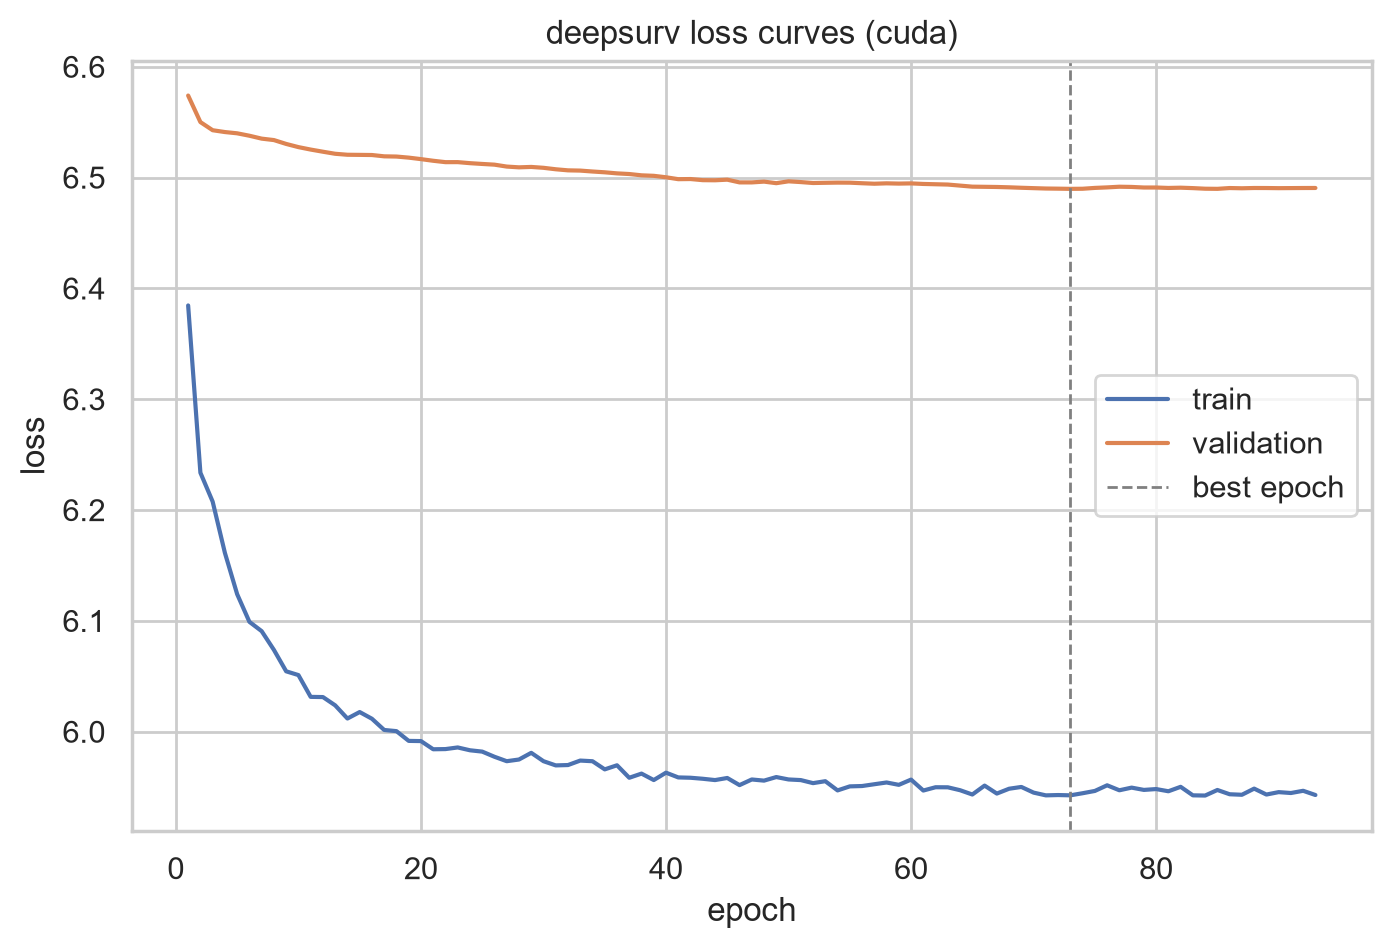

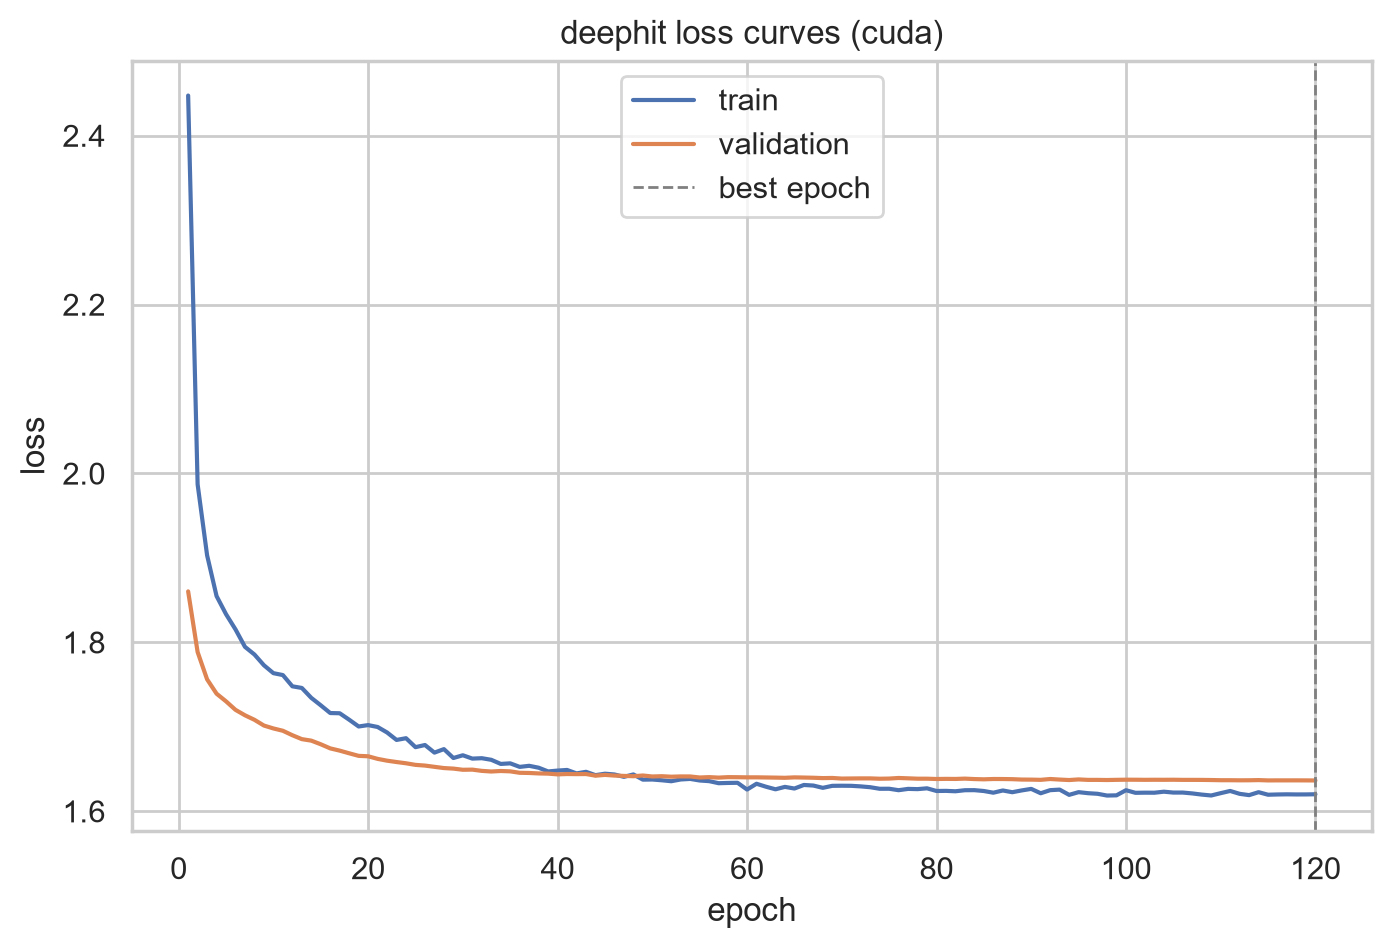

In [7]:
for n in ("deepsurv", "deephit"):
    display(Image(filename=str(resolve(cfg, "training_logs") / f"{n}_loss_curve.png"), width=600))

## 6. Evaluation on the hold-out set

In [8]:
results = [evaluate.evaluate_model(m, split, cfg) for m in fitted.values()]
table = evaluate.metrics_table(results).set_index("model")
display(table.round(4).sort_values("c_index_uno", ascending=False))

2026-11-22 16:05:13,823 | INFO    | evaluate | kaplan_meier             C=0.5000 UnoC=0.5000 IBS=0.2139 AUC@90=0.5000  (0.0s, cpu)


2026-11-22 16:05:13,938 | INFO    | evaluate | nelson_aalen             C=0.5000 UnoC=0.5000 IBS=0.2139 AUC@90=0.5000  (0.0s, cpu)


2026-11-22 16:05:14,070 | INFO    | evaluate | coxph                    C=0.6735 UnoC=0.6602 IBS=0.1843 AUC@90=0.7192  (5.2s, cpu)


2026-11-22 16:05:14,202 | INFO    | evaluate | weibull_aft              C=0.6738 UnoC=0.6605 IBS=0.1839 AUC@90=0.7194  (0.3s, cpu)


2026-11-22 16:05:14,337 | INFO    | evaluate | lognormal_aft            C=0.6828 UnoC=0.6617 IBS=0.1852 AUC@90=0.7419  (0.6s, cpu)


2026-11-22 16:05:39,344 | INFO    | evaluate | random_survival_forest   C=0.6769 UnoC=0.6631 IBS=0.1794 AUC@90=0.7458  (22.5s, cpu)


2026-11-22 16:05:39,535 | INFO    | evaluate | xgboost_cox              C=0.6843 UnoC=0.6704 IBS=0.1804 AUC@90=0.7376  (1.2s, cuda)


2026-11-22 16:05:39,780 | INFO    | evaluate | xgboost_aft              C=0.6898 UnoC=0.6712 IBS=0.1983 AUC@90=0.7515  (0.4s, cuda)


2026-11-22 16:05:39,959 | INFO    | evaluate | deepsurv                 C=0.6819 UnoC=0.6692 IBS=0.1807 AUC@90=0.7338  (2.8s, cuda)


2026-11-22 16:05:40,126 | INFO    | evaluate | deephit                  C=0.6855 UnoC=0.6680 IBS=0.1926 AUC@90=0.7451  (4.1s, cuda)


,device,train_seconds,c_index_harrell,c_index_uno,integrated_brier_score,one_minus_ibs,mean_time_auc,auc_30d,auc_90d,auc_180d,auc_365d
model,,,,,,,,,,,
xgboost_aft,cuda,0.407,0.6898,0.6712,0.1983,0.8017,0.7474,0.7733,0.7515,0.7357,0.7406
xgboost_cox,cuda,1.152,0.6843,0.6704,0.1804,0.8196,0.7417,0.7398,0.7376,0.7379,0.7602
deepsurv,cuda,2.807,0.6819,0.6692,0.1807,0.8193,0.7393,0.7309,0.7338,0.7399,0.7658
deephit,cuda,4.124,0.6855,0.6680,0.1926,0.8074,0.7482,0.7835,0.7451,0.7244,0.7698
random_survival_forest,cpu,22.496,0.6769,0.6631,0.1794,0.8206,0.7499,0.7781,0.7458,0.7371,0.7632
lognormal_aft,cpu,0.564,0.6828,0.6617,0.1852,0.8148,0.7374,0.7735,0.7419,0.7278,0.7188
weibull_aft,cpu,0.261,0.6738,0.6605,0.1839,0.8161,0.7273,0.7260,0.7194,0.7244,0.7519
coxph,cpu,5.242,0.6735,0.6602,0.1843,0.8157,0.7267,0.7264,0.7192,0.7233,0.7505
nelson_aalen,cpu,0.006,0.5000,0.5000,0.2139,0.7861,0.5000,0.5000,0.5000,0.5000,0.5000


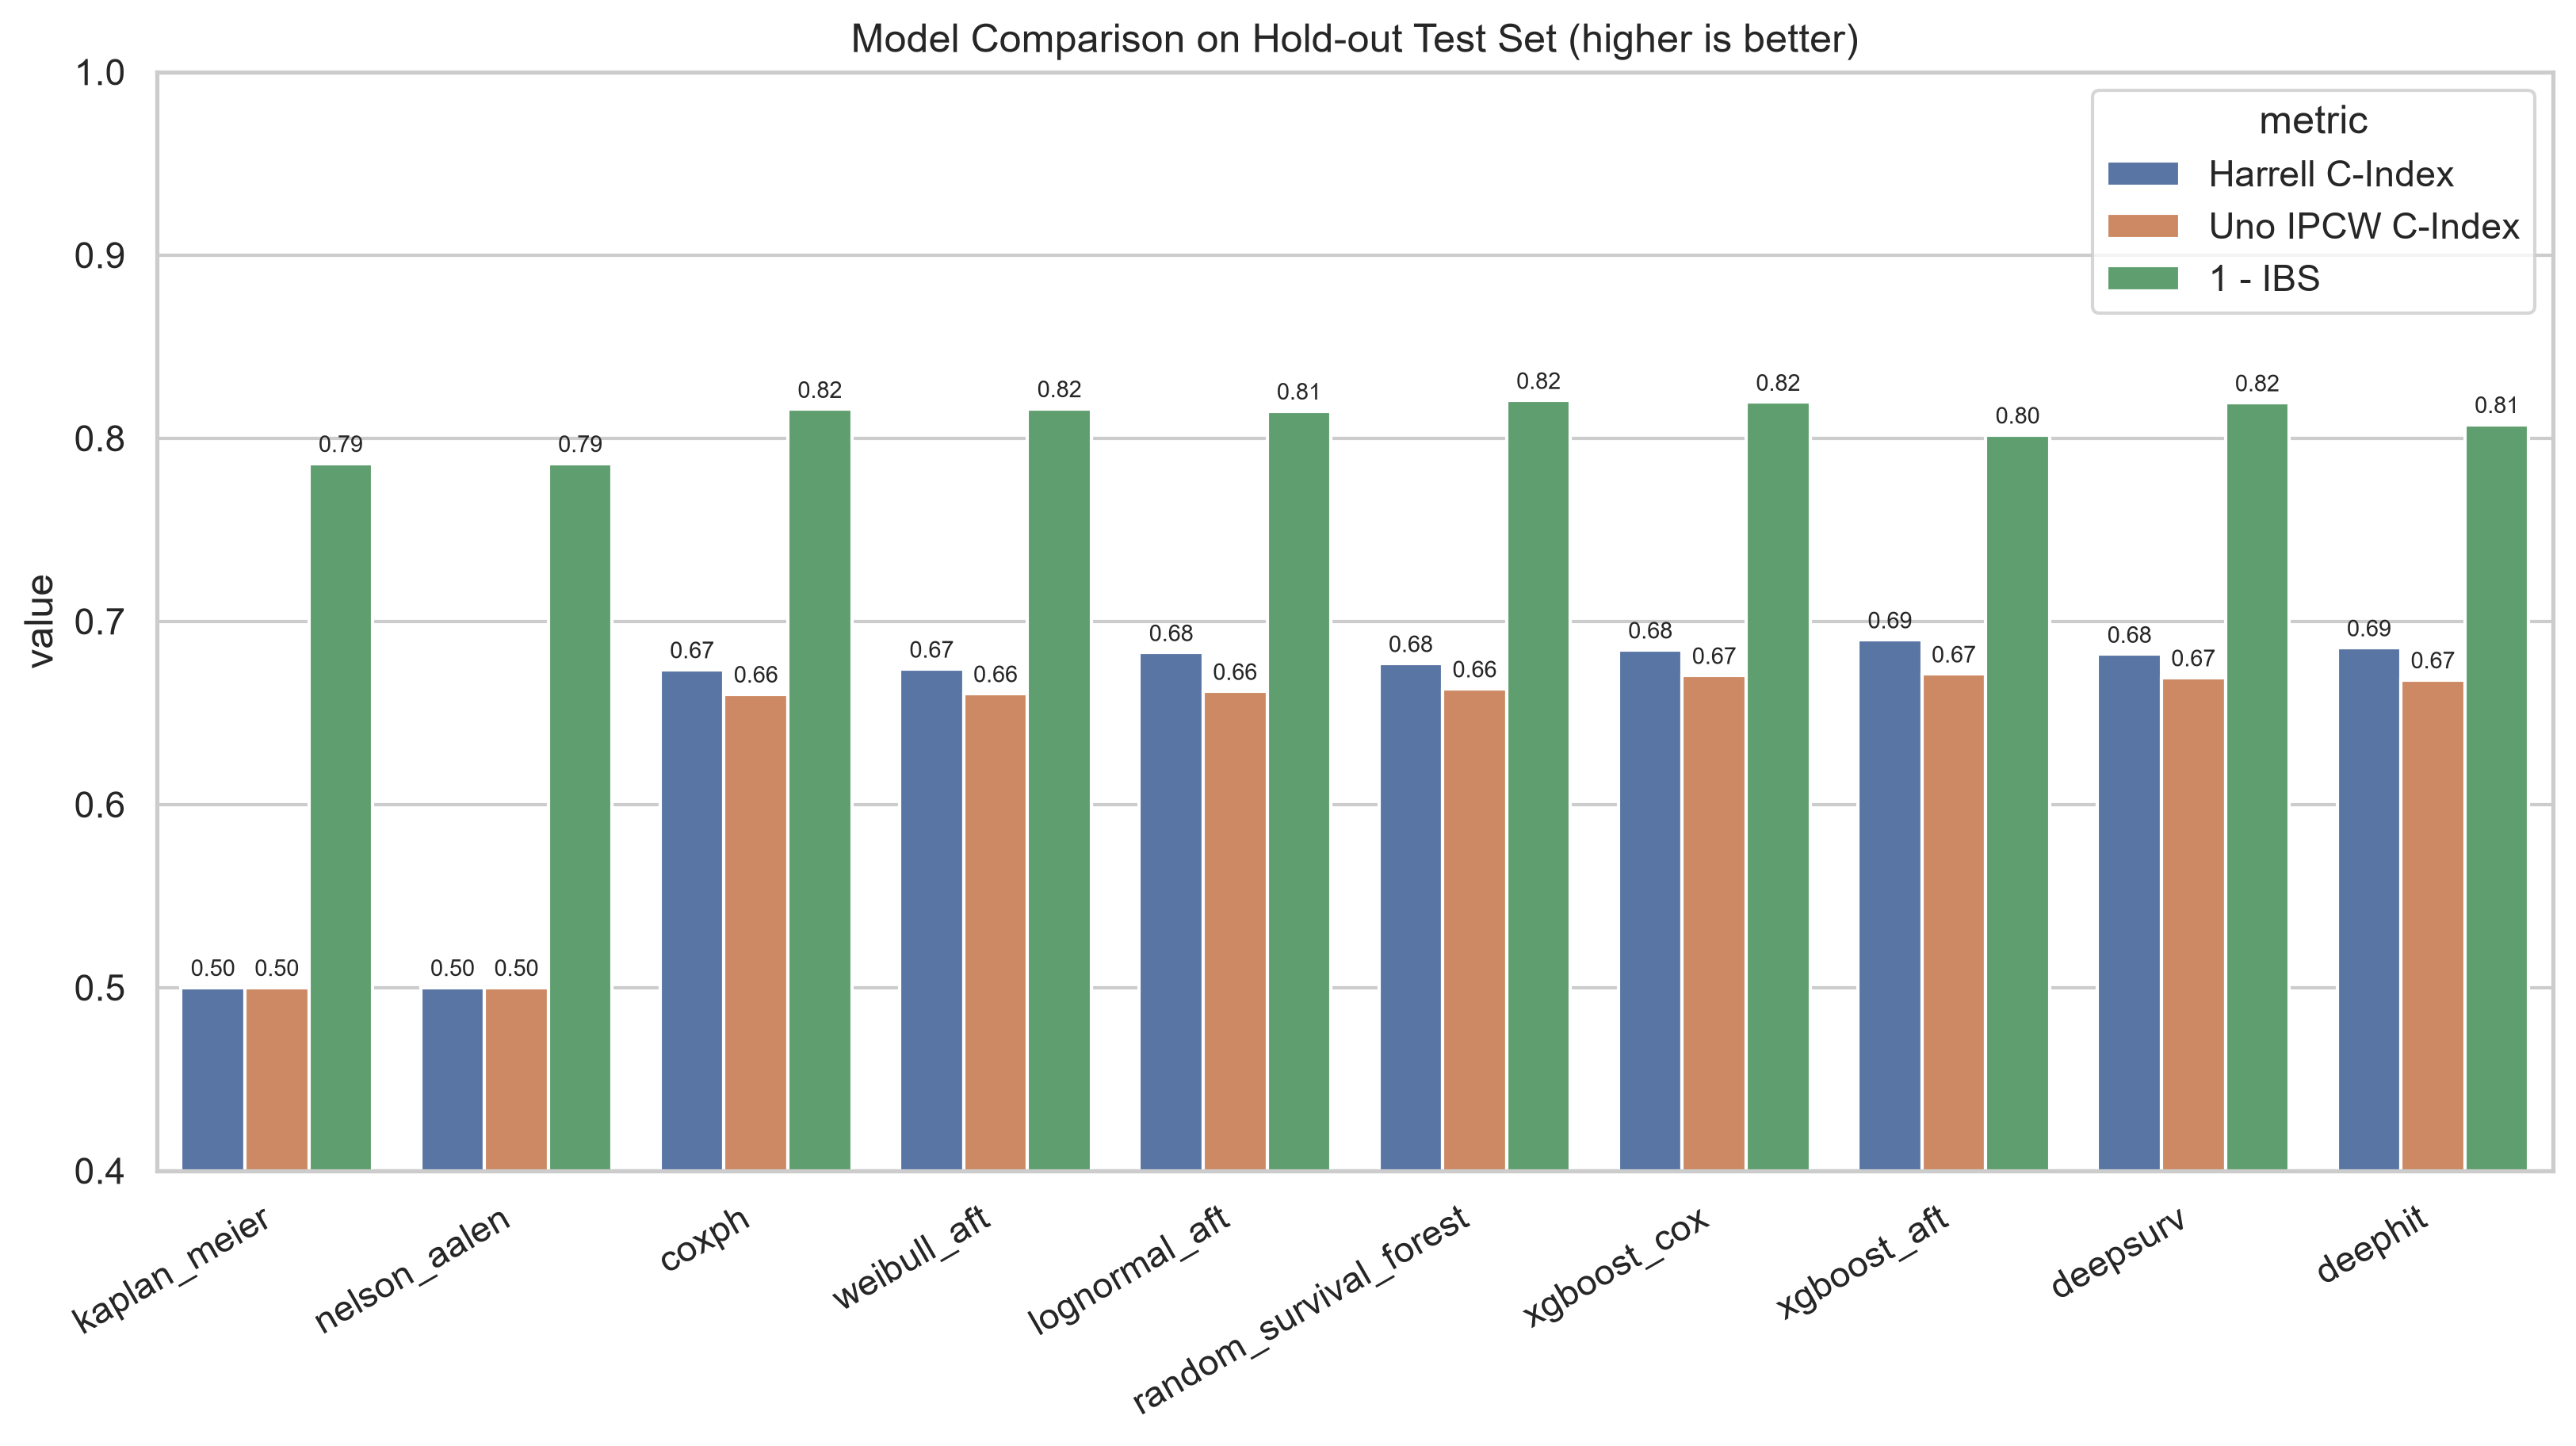

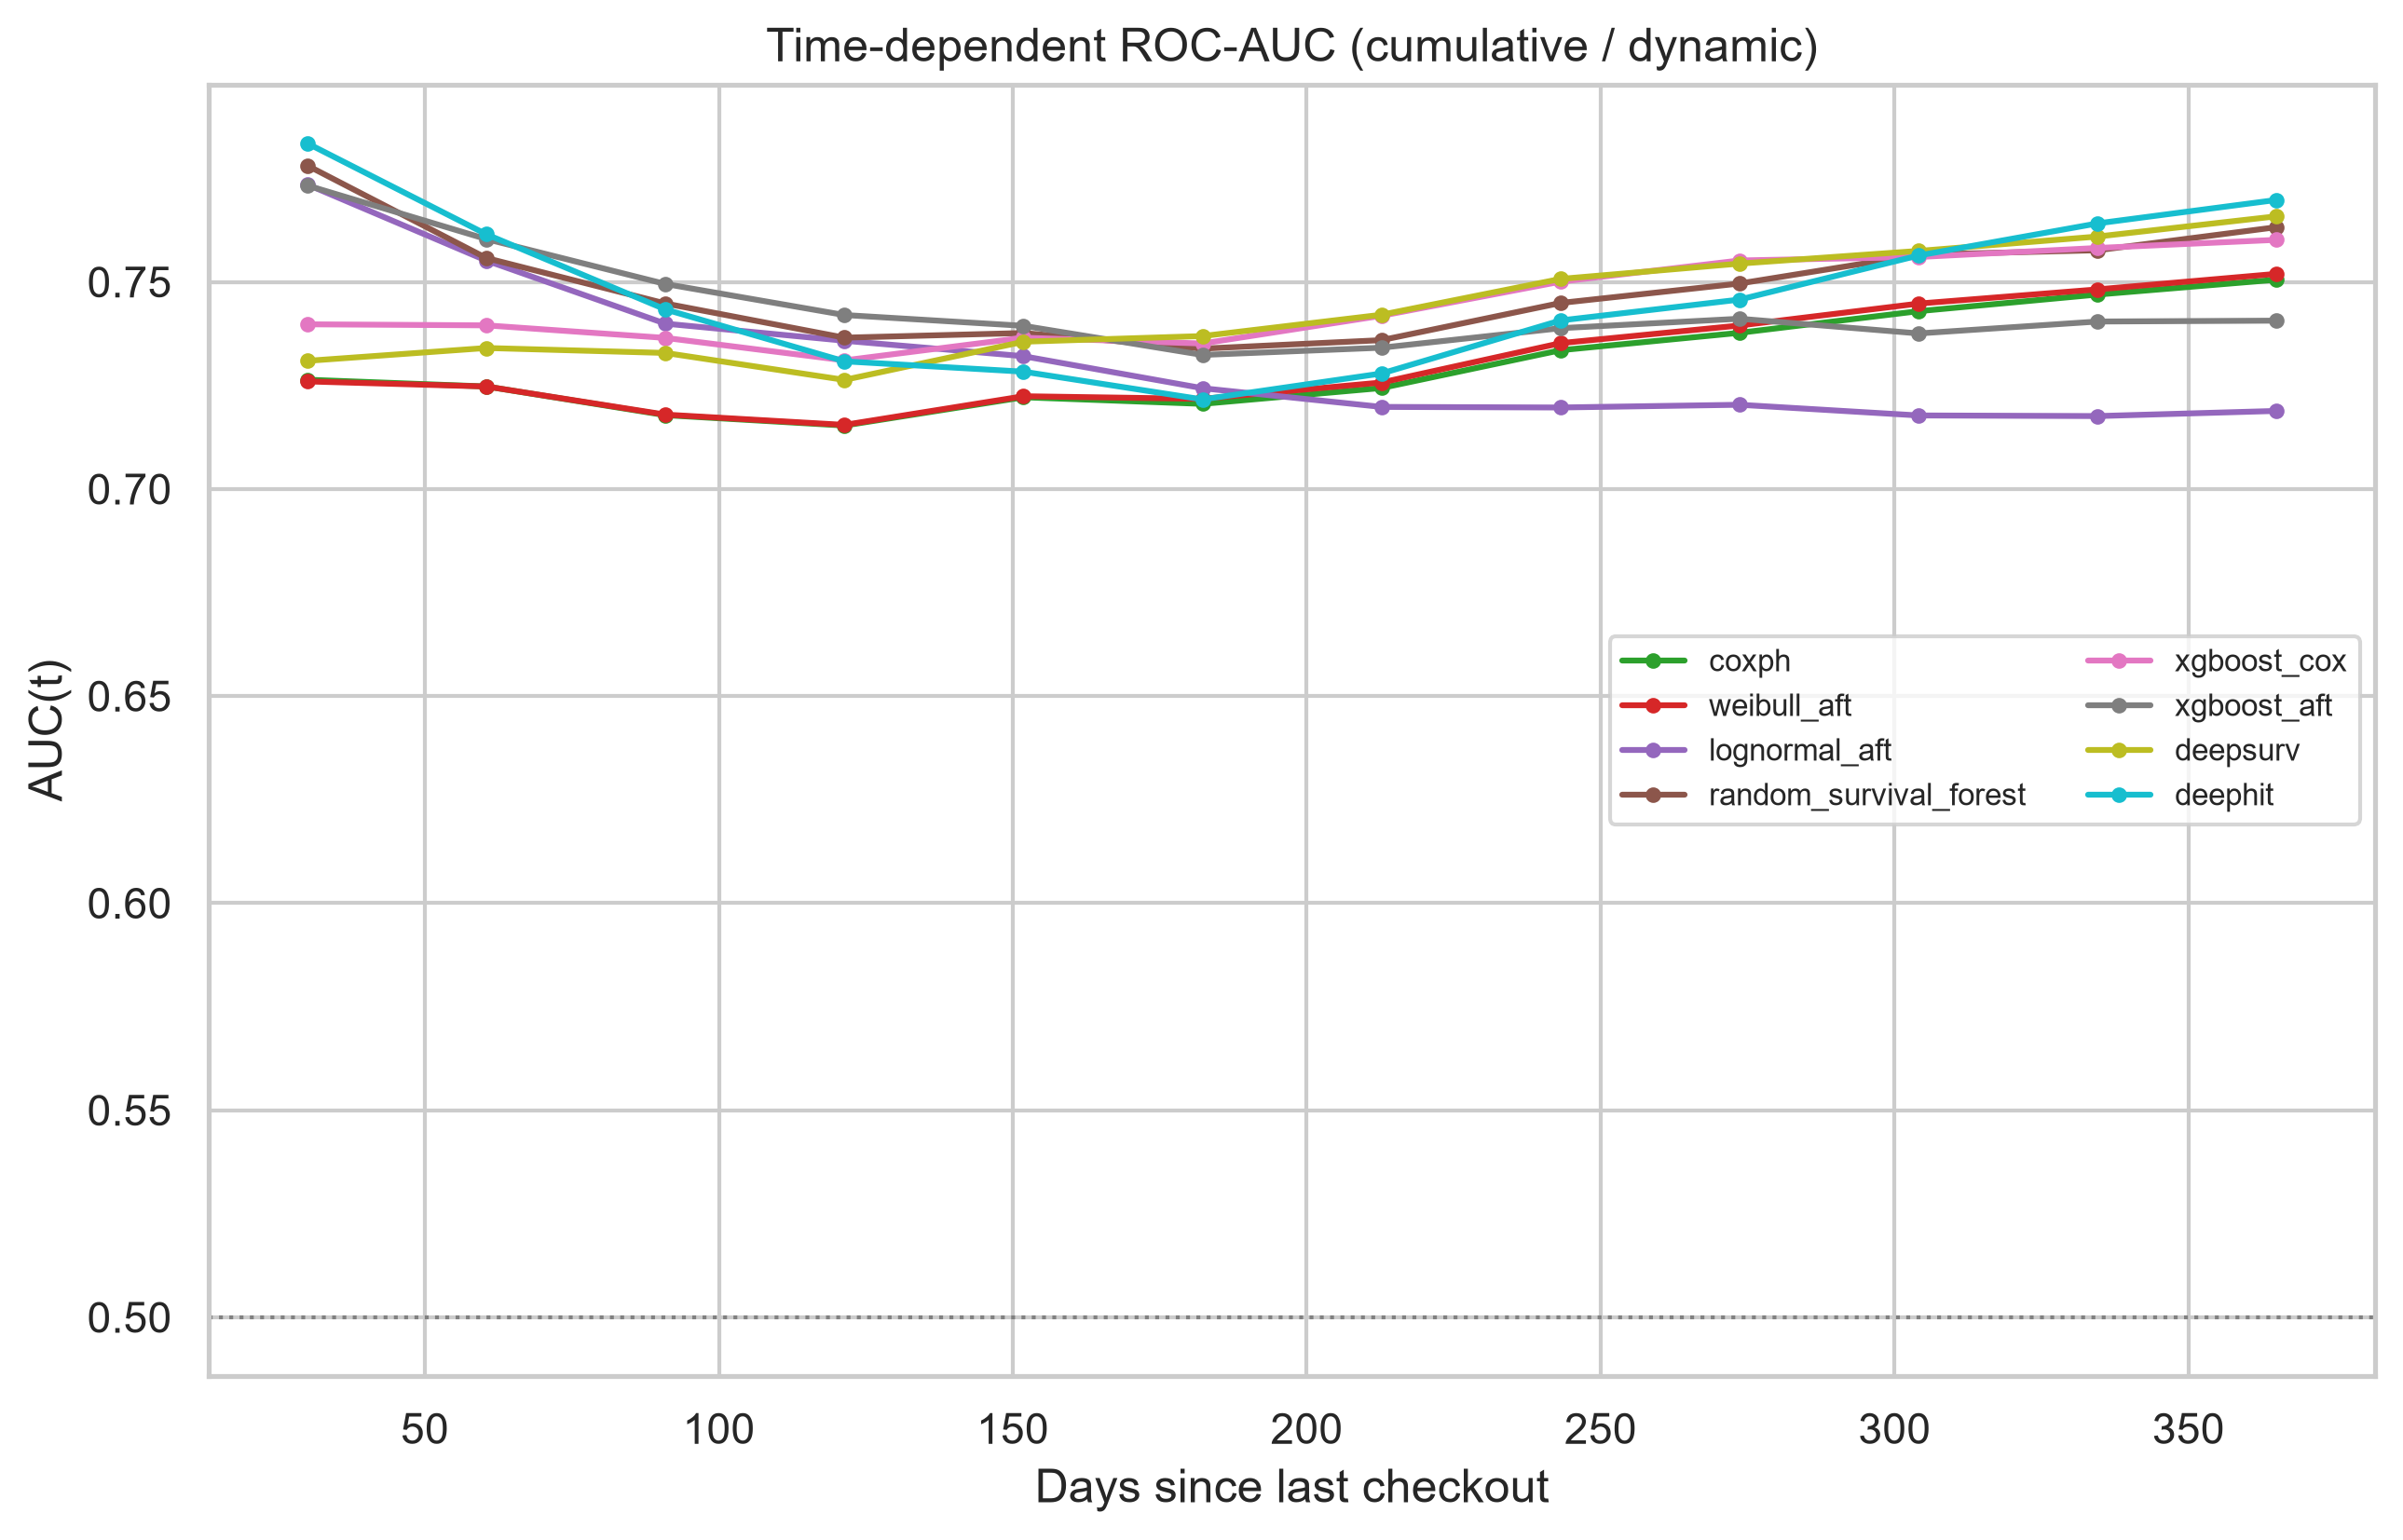

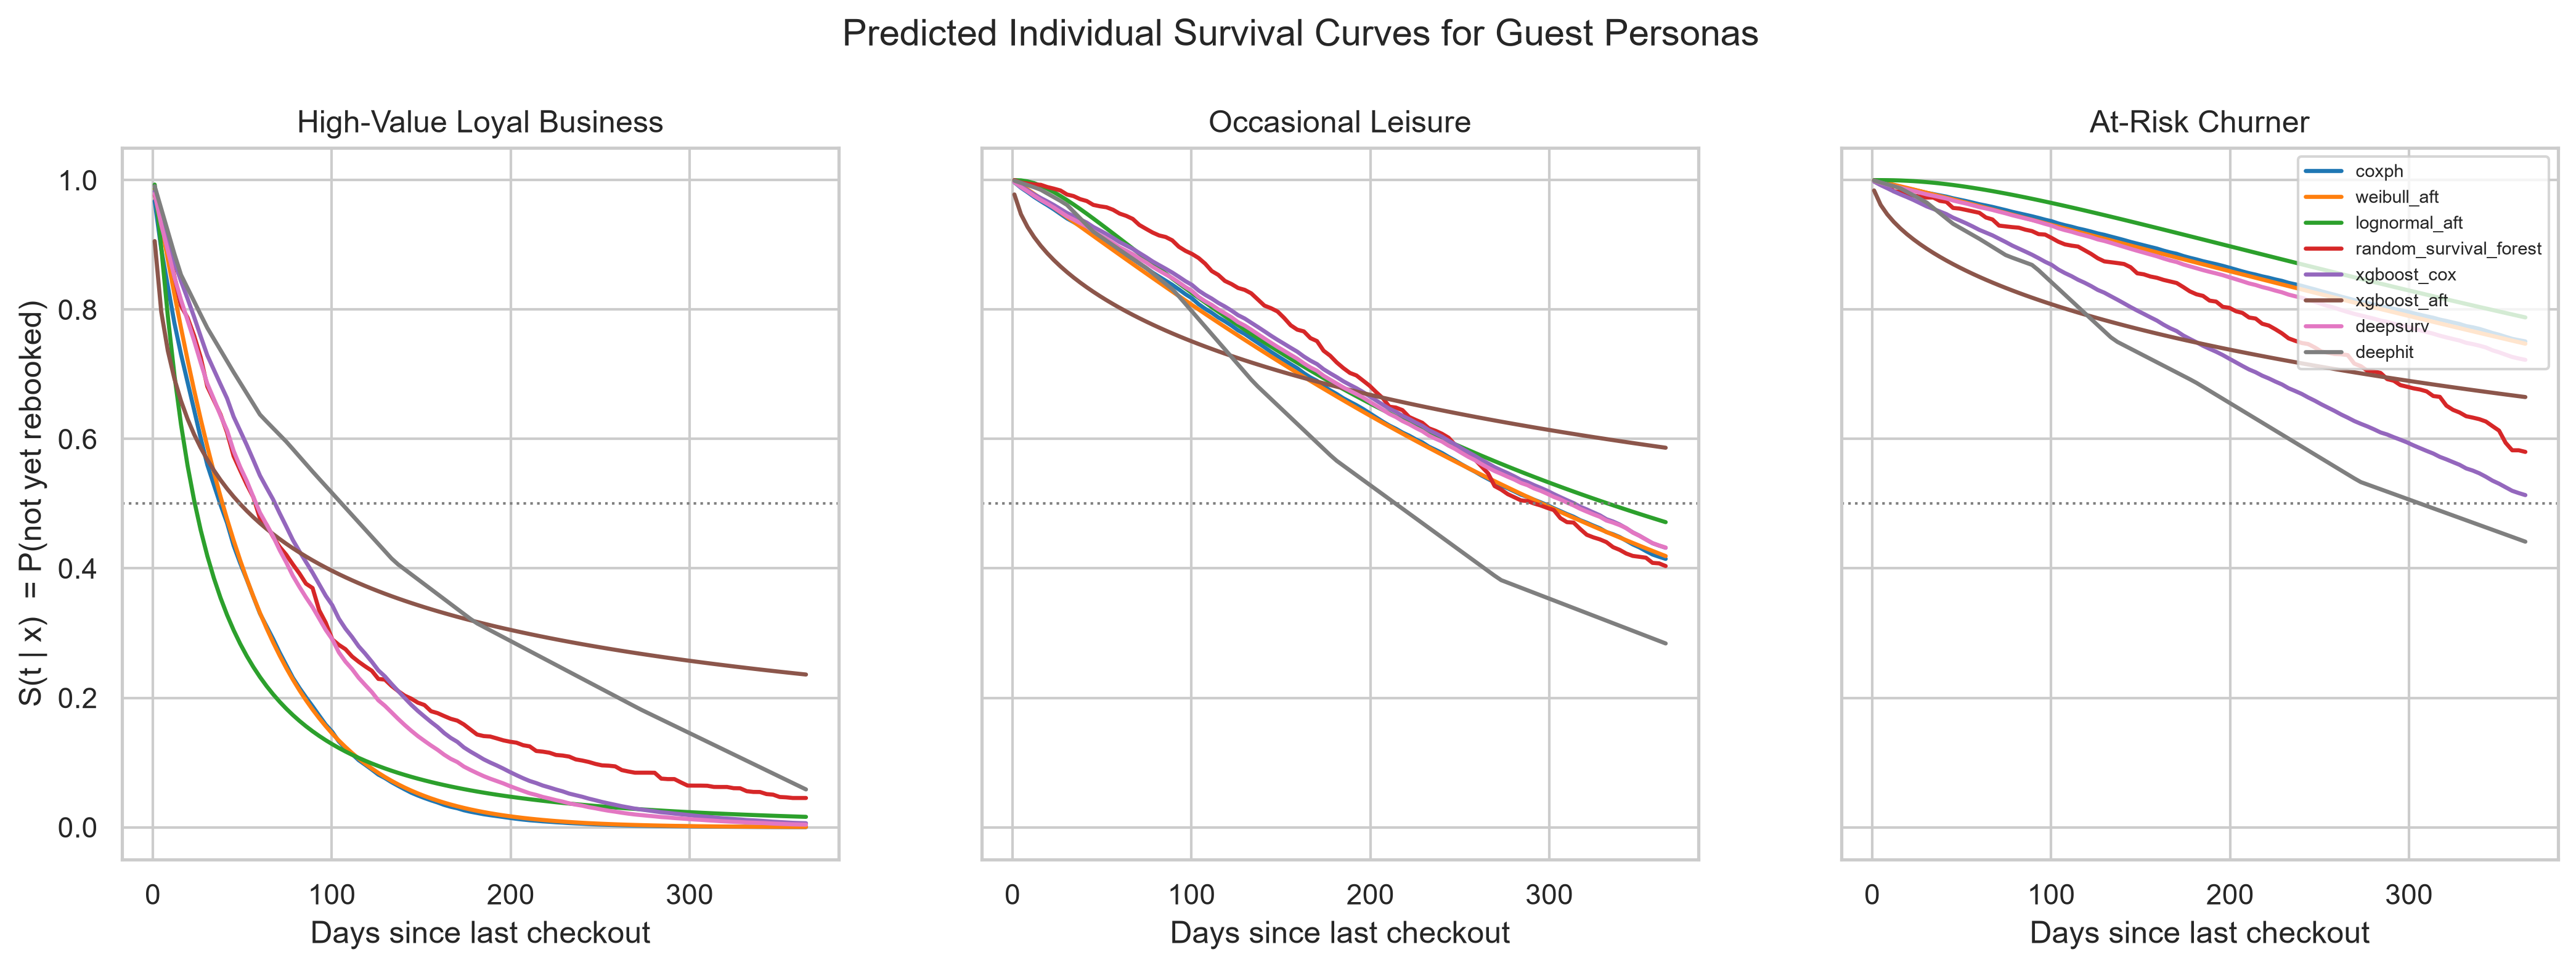

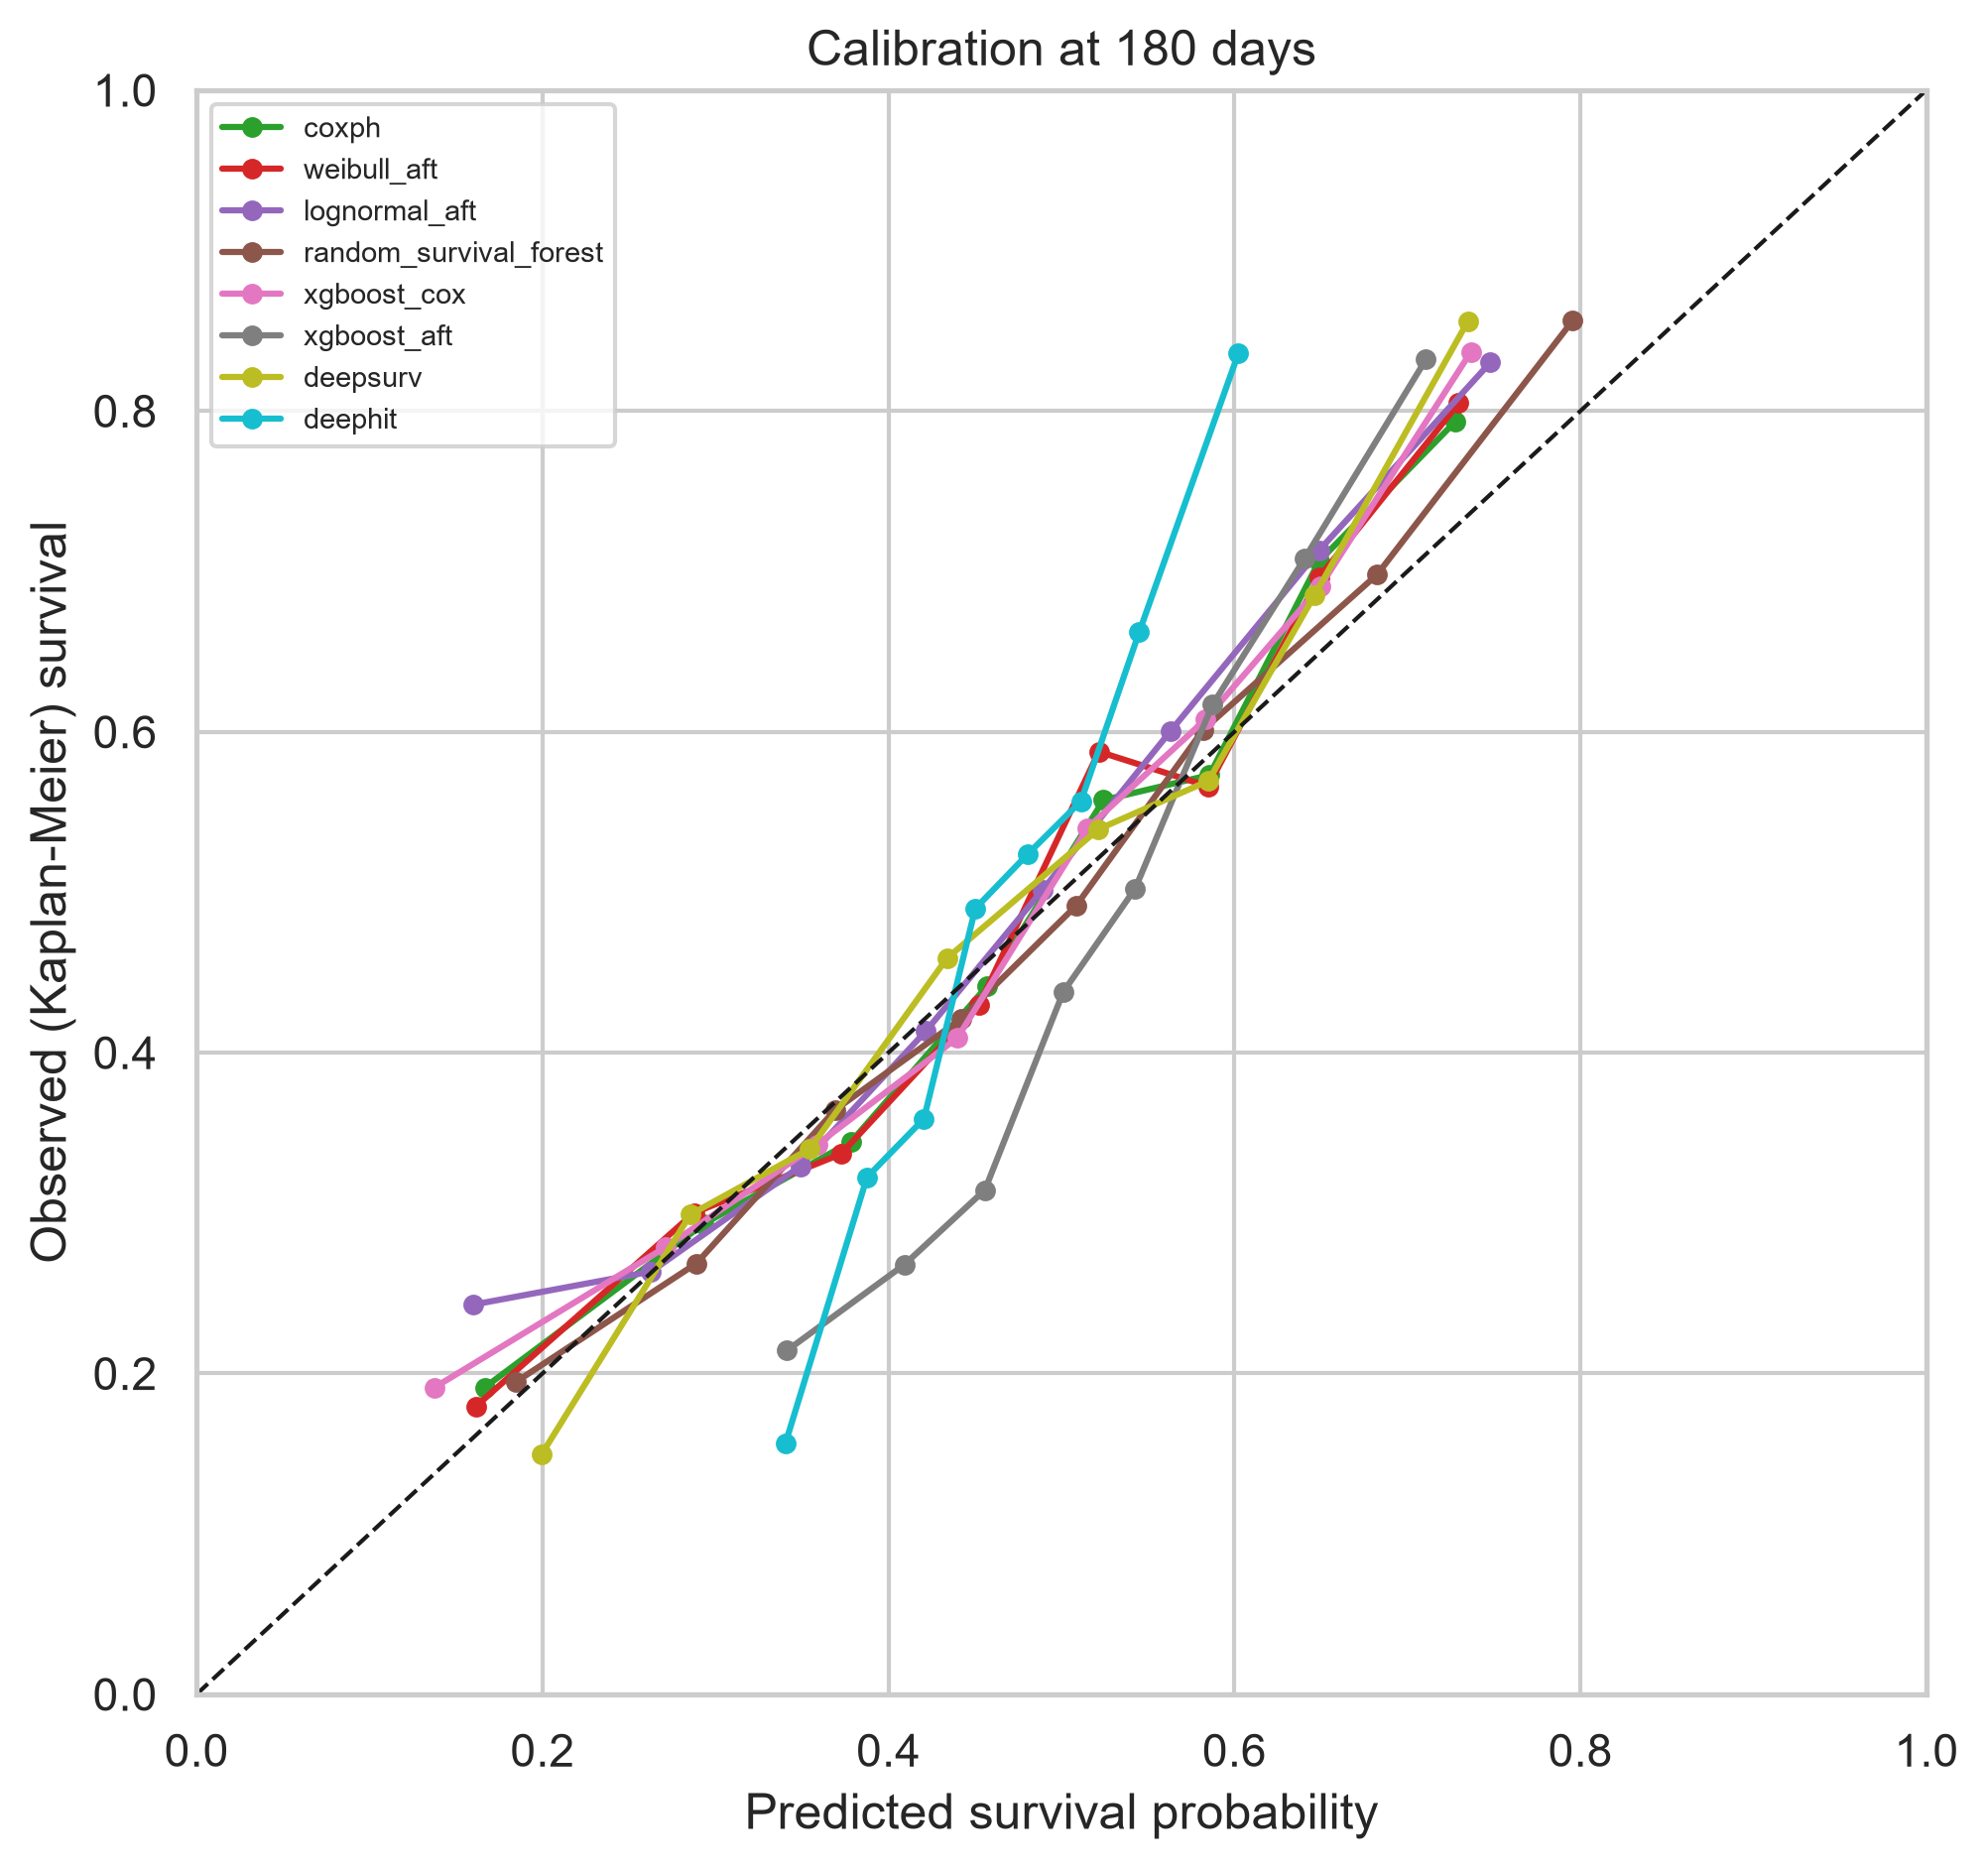

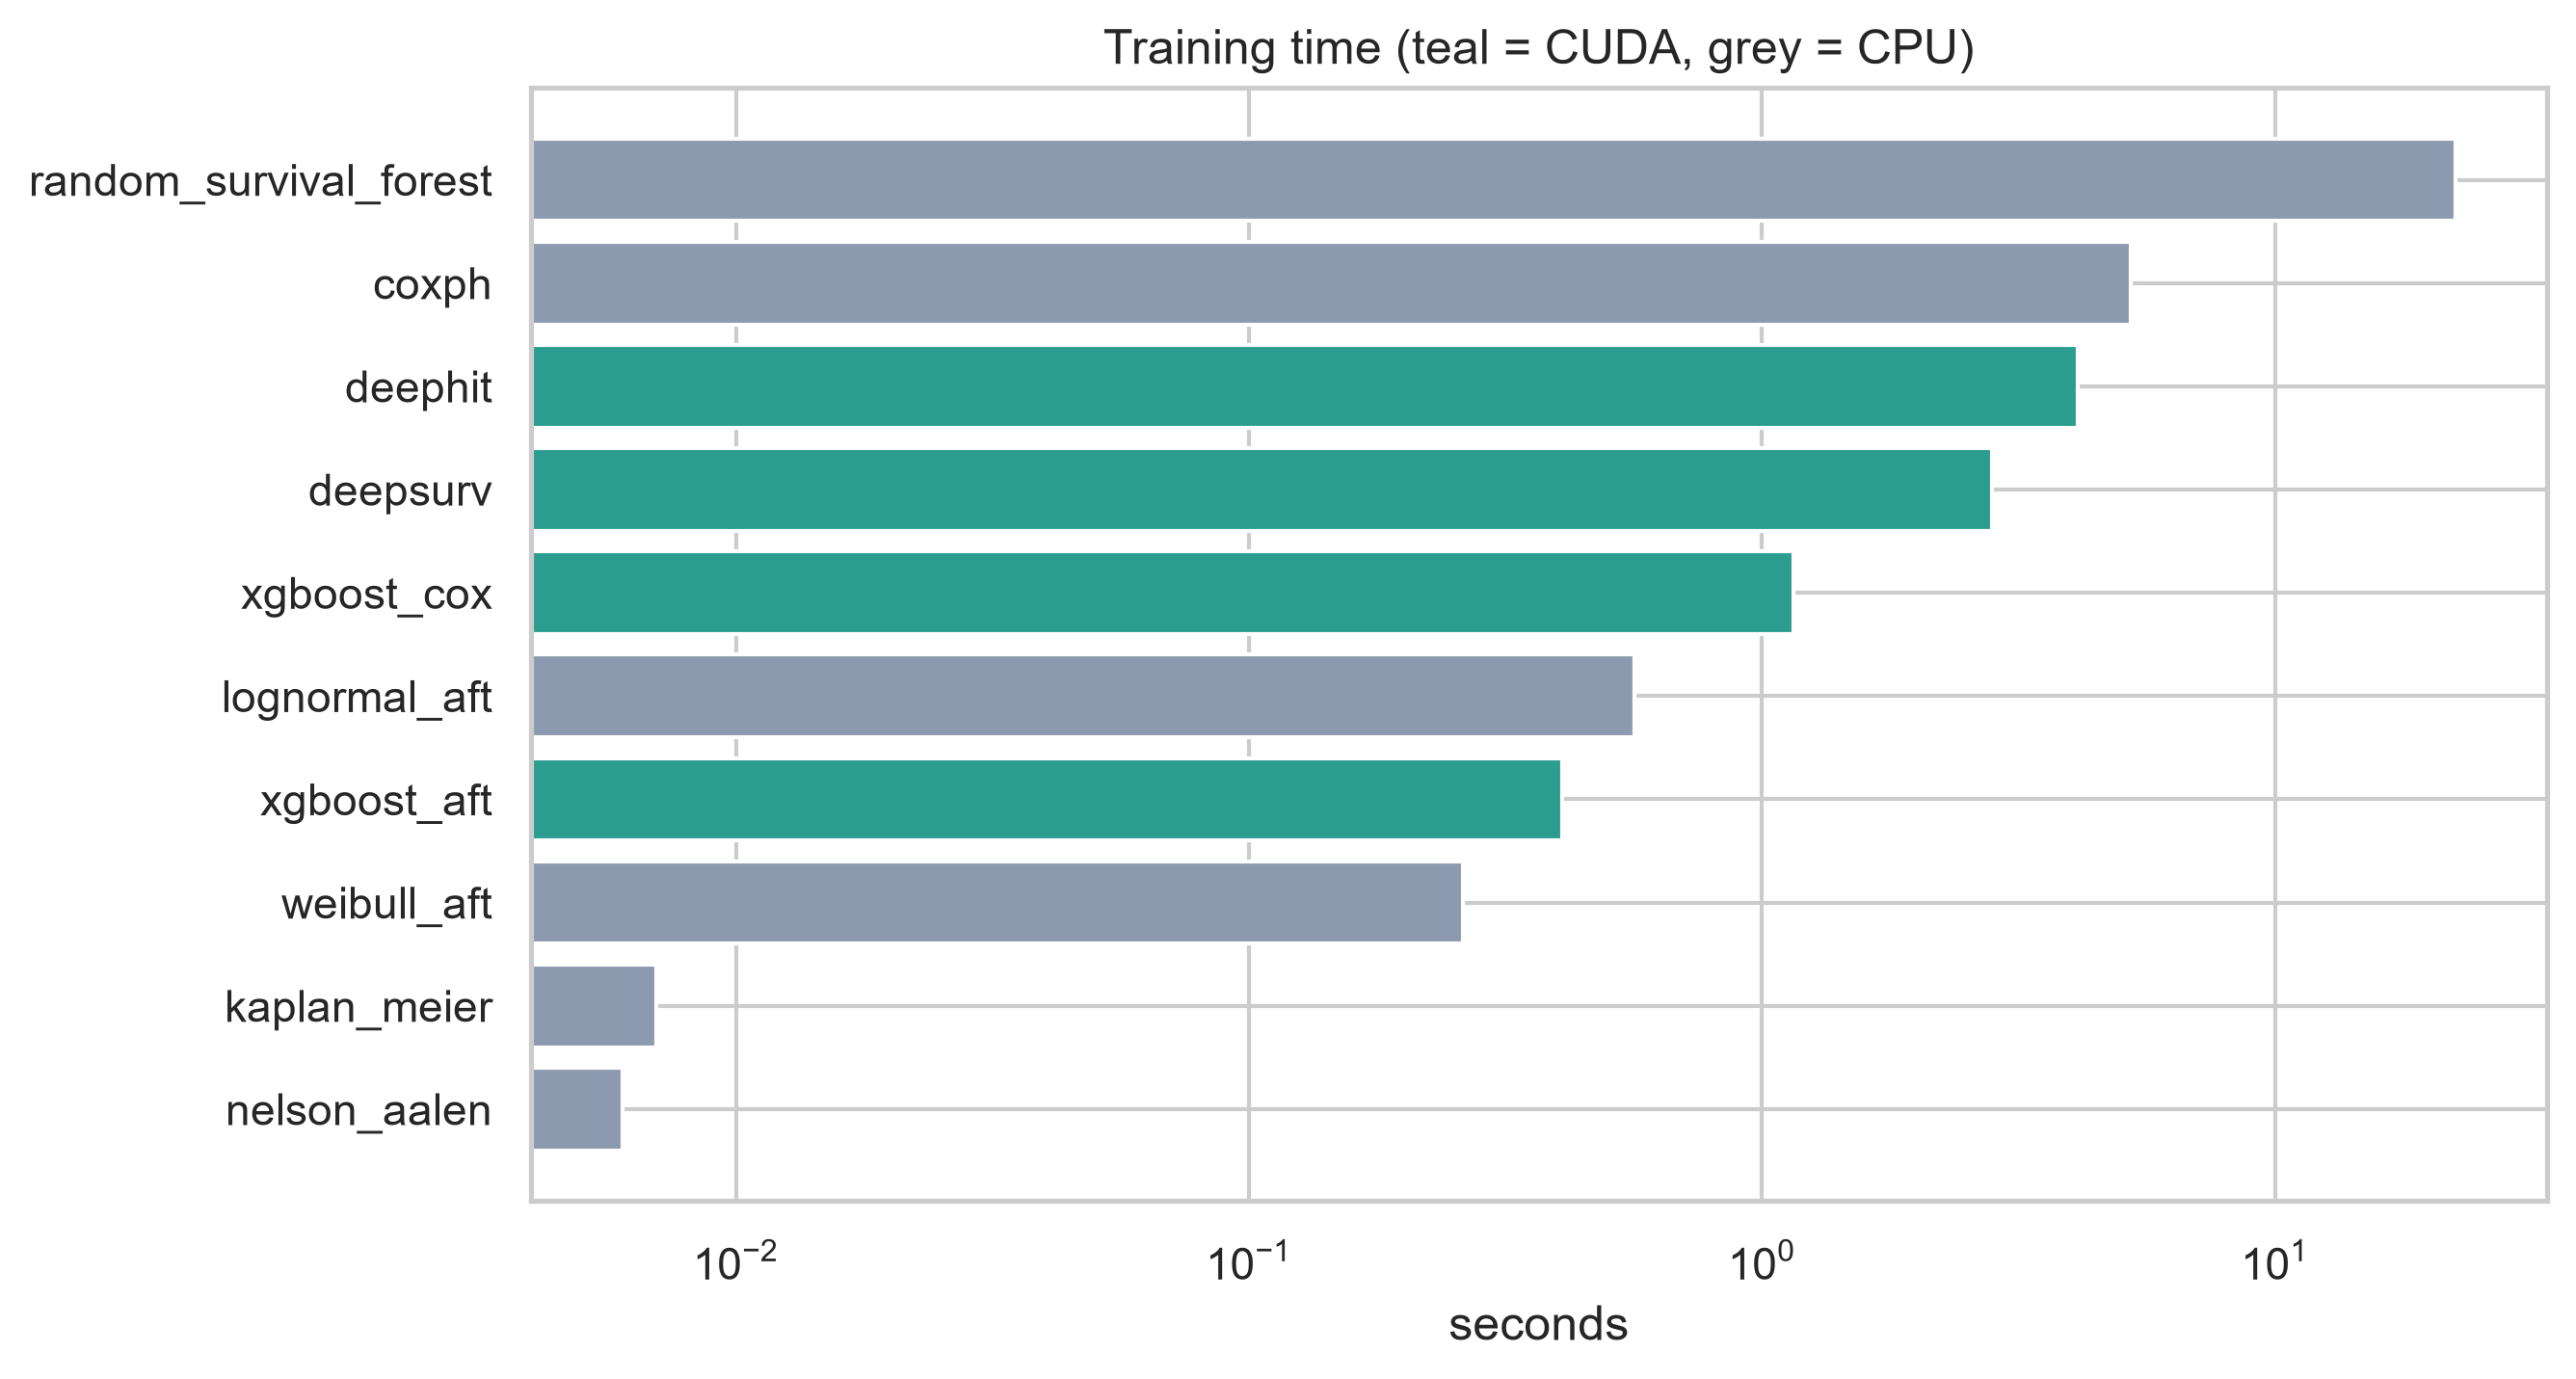

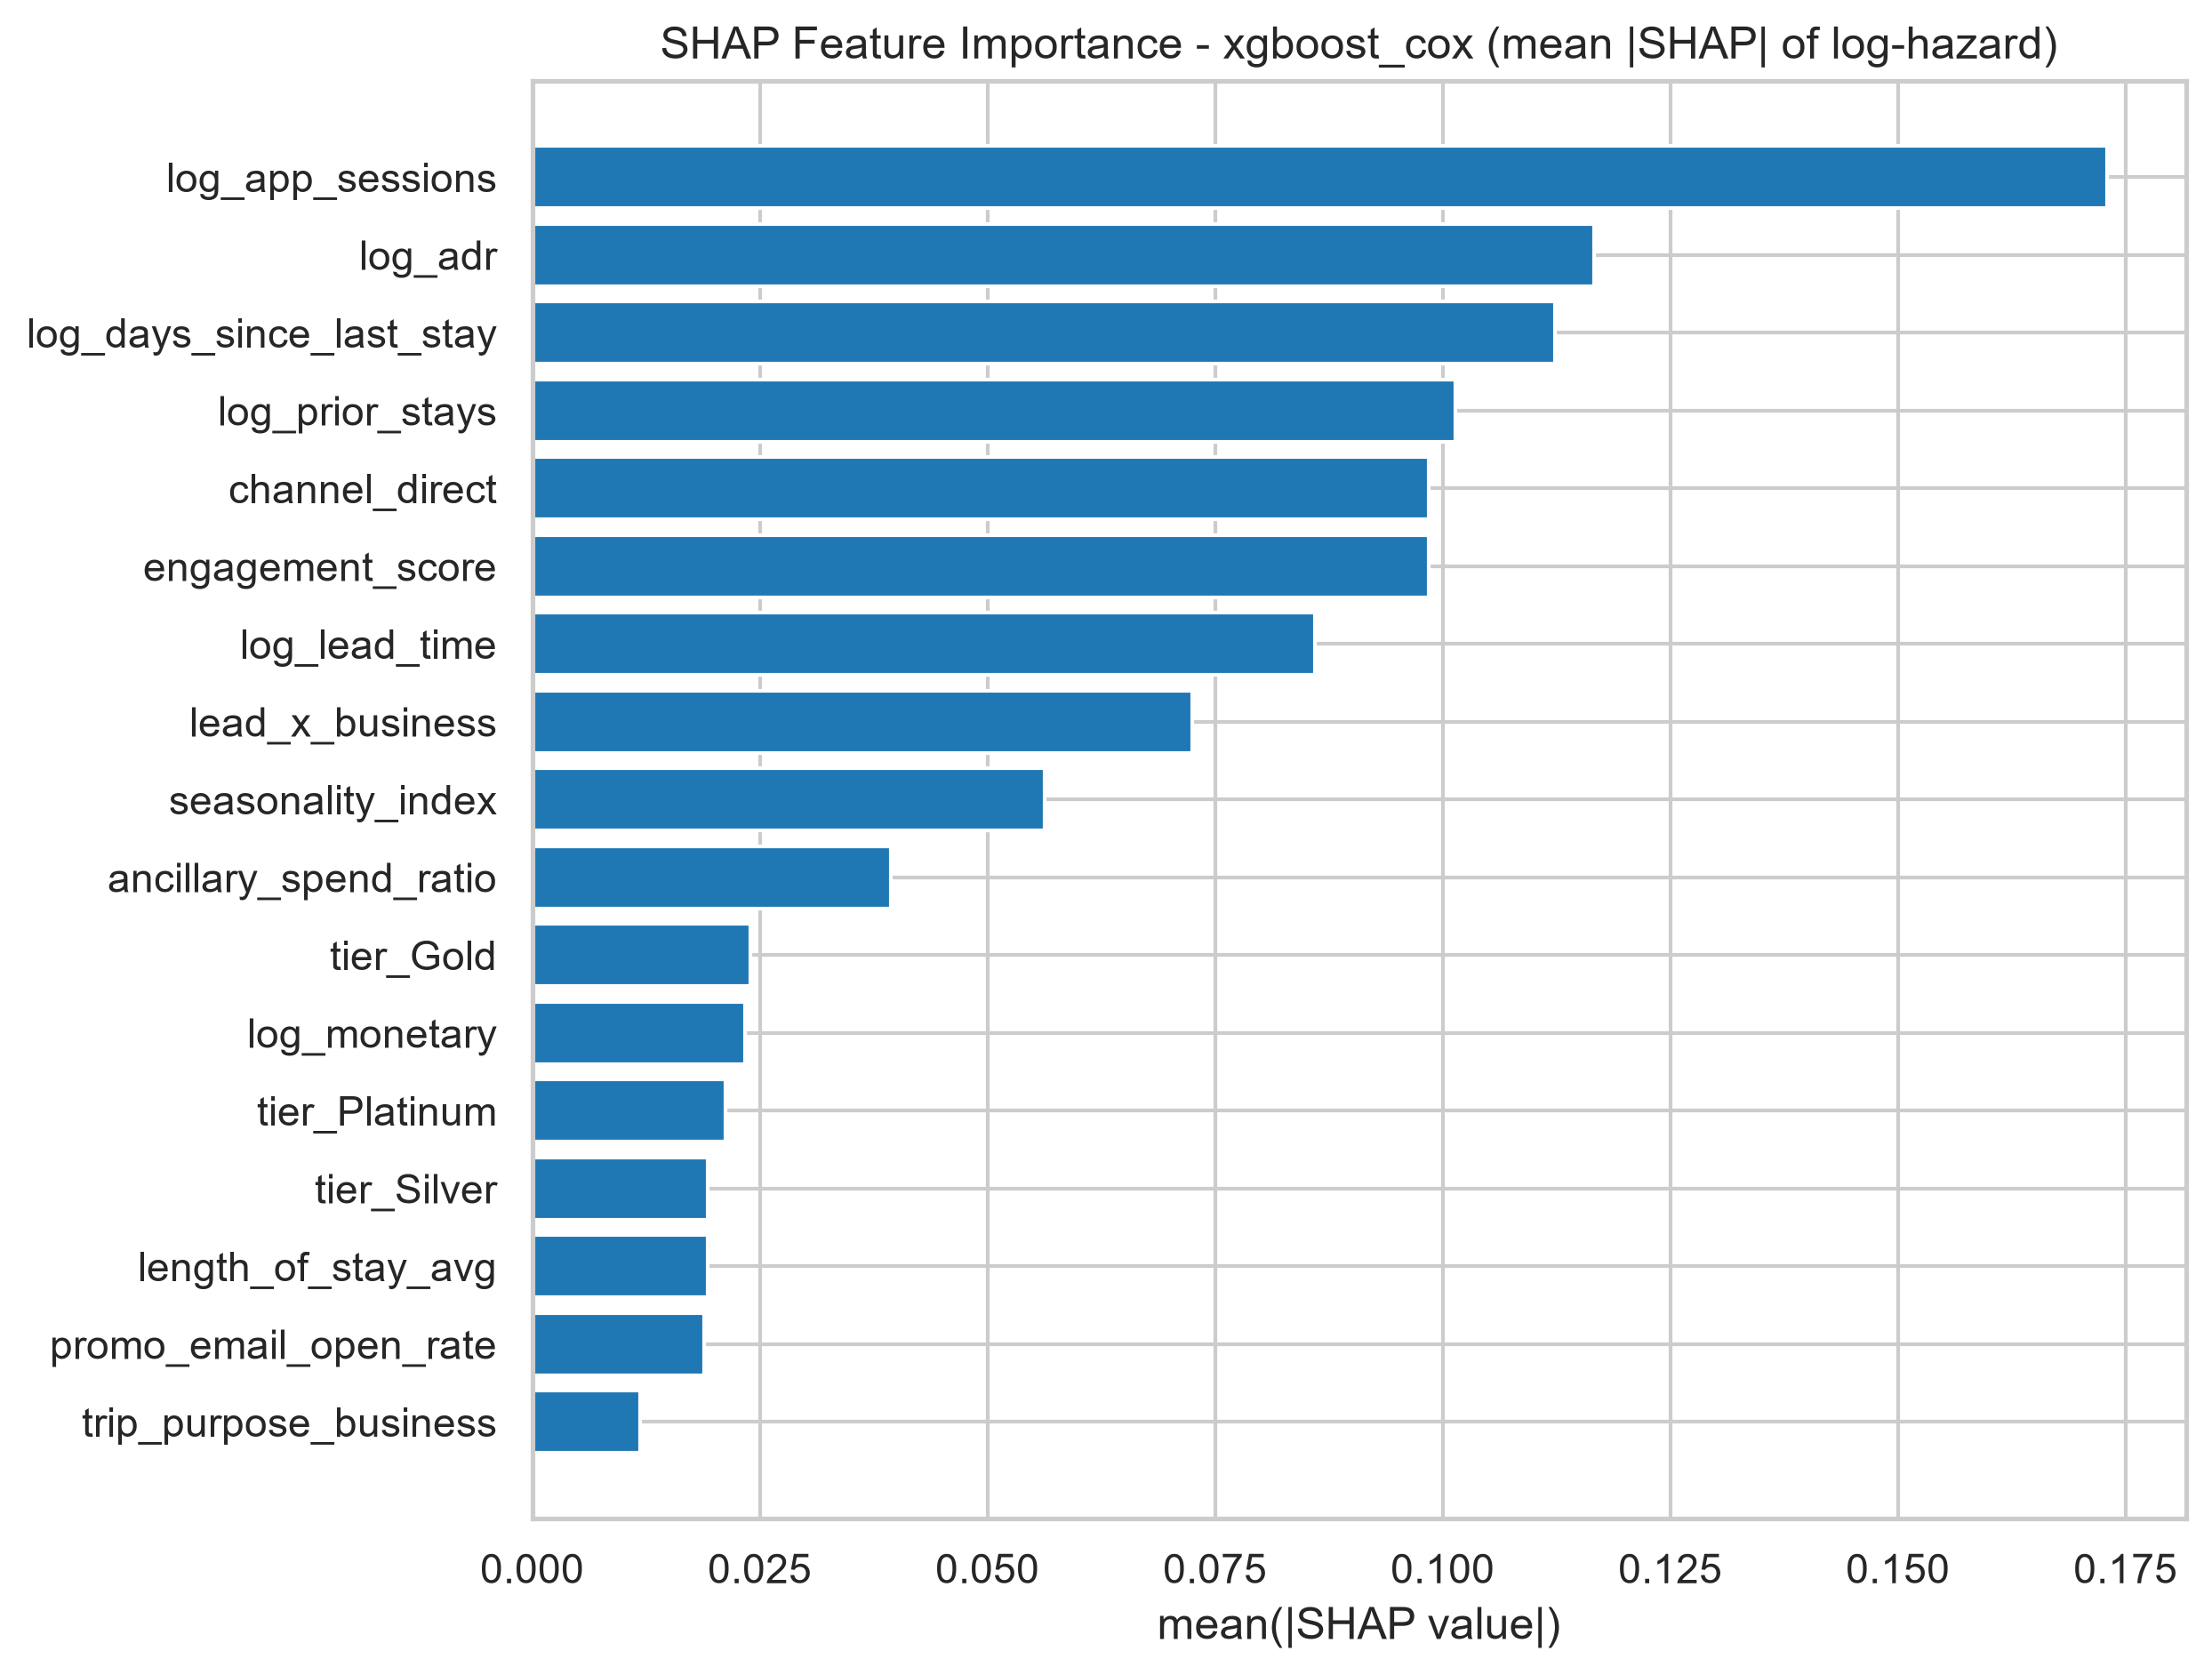

In [9]:
g = resolve(cfg, "comparison_graphs")
ps = [evaluate.plot_metric_bars(results, g), evaluate.plot_time_auc(results, cfg, g),
      evaluate.plot_personas(fitted, split["preprocessor"], g), evaluate.plot_calibration(fitted, split, 180, g),
      evaluate.plot_training_times(results, g), evaluate.plot_shap_xgb(fitted["xgboost_cox"], split["X_test"], g)]
for p in ps:
    if p: display(Image(filename=str(p), width=800))

## 7. Summary

In [10]:
cand = table.drop(index=list(BASELINES))
best = cand[cand.integrated_brier_score < 0.25].sort_values(["c_index_uno", "integrated_brier_score"],
                                                            ascending=[False, True]).index[0]
print("Best model by Uno C-index (IBS < 0.25):", best)
table.reset_index().to_csv(NB_OUT / "training_logs" / "notebook_model_comparison.csv", index=False)

Best model by Uno C-index (IBS < 0.25): xgboost_aft
